<a href="https://colab.research.google.com/github/RxSaturn/PDI_Tetrazolio_MultiEspecie_Interativo/blob/main/PDI_Tetrazolio_MultiEspecie_Interativo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Avaliação Comparativa de Métodos de Visão Computacional para Análise de Viabilidade de Sementes via Teste de Tetrazólio

**Instituição:** Instituto Federal de Educação, Ciência e Tecnologia de Minas Gerais (IFMG) — Campus Bambuí  
**Evento:** Jornada Científica da XVIII Semana de Ciência e Tecnologia (Edição 2026)  
**Área:** Engenharia de Computação — Processamento Digital de Imagens e Visão Computacional  
**Autores:** Henrique Augusto Gonçalves Fernandes, João Pedro Rodrigues de Lima, Henrique Evangelista Pimentel, Gustavo Silveira Dias  
**Orientador:** Prof. Bruno Alberto Soares Oliveira  
**Contato:** `henriqueag.fernandes@proton.me`

---

## Fundamentação Científica e Arquitetura Híbrida Multi-Espécie

A avaliação da viabilidade fisiológica de sementes pelo teste bioquímico de tetrazólio baseia-se na redução do sal incolor de cloreto de 2,3,5-trifeniltetrazólio (TTC) pelas enzimas desidrogenases dos tecidos respiratoriamente ativos, originando o composto insolúvel *trifenilformazan* de coloração róseo-carmim. Como a inspeção visual convencional é morosa, subjetiva e suscetível à fadiga do analista, este ambiente computacional implementa e avalia comparativamente **quatro paradigmas clássicos de Processamento Digital de Imagens (PDI)** estruturados sobre uma arquitetura híbrida e extensível:

1. **Café (*Coffea arabica* L.):** Calibrado segundo o protocolo da Embrapa Café / UFLA ([Rosa et al., 2013](https://www.embrapa.br/busca-de-publicacoes/-/publicacao/975203/imagens-digitais-do-teste-de-tetrazolio-para-avaliar-a-qualidade-de-graos-de-cafe)), no qual embriões (TTC 0,5% a 30 °C por 3 h) e endospermas seccionados (TTC 0,1% a 30 °C por 24 h) têm a viabilidade quantificada pela fração relativa de área corada, com referencial morfológico complementar no [Coffee Bean Dataset — Kaggle](https://www.kaggle.com/datasets/gpiosenka/coffee-bean-dataset-resized-224-x-224).
2. **Soja (*Glycine max* (L.) Merrill):** Fundamentado nos manuais da Embrapa Soja ([França-Neto; Krzyzanowski; Costa, 1998](https://www.embrapa.br/busca-de-publicacoes/-/publicacao/460029/the-tetrazolium-test-for-soybean-seeds); [Documento 449, 2022](https://www.infoteca.cnptia.embrapa.br/infoteca/bitstream/doc/1148061/1/DOCUMENTO-449-on-line.pdf)) e na modelagem computacional de germinação ([Revista Ciência Agronômica, 2025](https://www.scielo.br/j/rca/a/ShdLS9SJxvW39skj85Jm8qn/?lang=en)), discriminando tecido vivo vigoroso (vermelho-carmim brilhante), tecido em deterioração aguda por hiper-redução (carmim escuro intenso) e tecido necrosado ou morto (branco-leitoso/amarelado), com suporte ao conjunto [Soybean Seeds — Mendeley Data](https://data.mendeley.com/datasets/v6vzvfszj6).
3. **Generalização para Feijão Comum (*Phaseolus spp.*, família Fabaceae):** Estende a arquitetura híbrida às prescrições oficiais das **Regras para Análise de Sementes — RAS** (BRASIL, MAPA, 2009, Quadro 6.1, p. 232 e p. 275; BHERING et al., 1999), incorporando o pré-umedecimento entre papel (18–24 h a 25 °C) ou pré-condicionamento em caixa *gerbox* com tela modificada sobre lâmina d'água (16–24 h a 20–25 °C), a coloração da semente intacta em solução de tetrazólio a 0,075%–0,1% (2–4 h a 40 °C no escuro), o corte longitudinal através do eixo embrionário com remoção do tegumento e o critério topográfico normativo de viabilidade ($\le 1/2$ da área cotiledonar não colorida ou necrosada, $\le 1/3$ da ponta da radícula e $\le 1/4$ da plúmula).

### Interface Padronizada dos Quatro Pipelines Analíticos
Todos os algoritmos operam sobre uma imagem de entrada no espaço BGR (`img_bgr`) e retornam uma estrutura de saída homogênea composta por:
* **`mascara_sementes`**: máscara binária de segmentação dos exemplares com supressão do plano de fundo;
* **`mascara_corada`**: máscara binária das regiões biologicamente ativas coradas por *trifenilformazan*;
* **`df_sementes`**: tabela estruturada por exemplar contendo identificador, espécie, centróide, área total (px), área corada (px), fração relativa de tecido ativo e classe fisiológica predita (`Viável` ou `Inviável`);
* **`tempo_ms`**: latência total de inferência por bandeja em milissegundos.


## 1. Ambiente Computacional, Perfis Paramétricos por Espécie e Regra de Decisão

Nesta seção são estabelecidas as dependências computacionais, a fixação de sementes aleatórias para reprodutibilidade determinística e a parametrização modular por cultura agrícola (`PERFIS_ESPECIE`). A separação explícita dos parâmetros bioquímicos e cromáticos permite que o mesmo núcleo algorítmico opere de modo consistente sobre culturas distintas sem alteração estrutural dos pipelines.


In [ ]:
# Verificação de dependências no ambiente Google Colab
%pip install -q opencv-python-headless scipy pandas matplotlib ipywidgets


In [ ]:
import base64
import io
import os
import random
import sys
import time
from datetime import datetime
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import cv2
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import ndimage as ndi

# Fixação determinística de estado pseudoaleatório
SEMENTE = 42
random.seed(SEMENTE)
np.random.seed(SEMENTE)

# Diretórios de trabalho para registros laboratoriais, figuras e métricas
DATA_DIR_LAB = Path("dados_laboratorio_ifmg")
FIGURAS_DIR = Path("figuras_resultados")
RESULTADOS_DIR = Path("resultados_metricas")
for _d in (DATA_DIR_LAB, FIGURAS_DIR, RESULTADOS_DIR):
    _d.mkdir(parents=True, exist_ok=True)

print(
    f"Ambiente ativo | Python {sys.version.split()[0]} | "
    f"OpenCV {cv2.__version__} | NumPy {np.__version__} | Pandas {pd.__version__}"
)


Ambiente ativo | Python 3.13.18 | OpenCV 5.0.0 | NumPy 2.4.6 | Pandas 2.2.3


### 1.1 Calibração Bioquímica e Óptica por Espécie (*Fine-Tuning* Paramétrico)

Os limiares de viabilidade e as faixas cromáticas nos espaços HSV e CIELAB são encapsulados em `PERFIS_ESPECIE`. No caso de *Phaseolus spp.* (feijão comum), o limiar mínimo de tecido cotiledonar vivo (`0,50`) reflete diretamente o limite normativo de área máxima permitida de tecido não colorido ou necrosado definido no Quadro 6.1 das Regras para Análise de Sementes (BRASIL, 2009, p. 275; BHERING et al., 1999), aliado ao ajuste dos intervalos de matiz e saturação para o padrão róseo-carmim característico dos cotilédones após a remoção do tegumento.


In [ ]:
AREA_MINIMA_PX = 350  # Limite mínimo de área para filtragem morfológica de ruído residual

PERFIS_ESPECIE: Dict[str, Dict] = {
    "soja": {
        "nome_cientifico": "Glycine max (L.) Merrill",
        "limiar_viavel": 0.62,
        "limiar_hiperreducao": 0.35,
        "hue_low_max": 14,
        "hue_high_min": 162,
        "sat_min": 62,
        "val_vivo_min": 122,
        "val_escuro_min": 45,
        "a_vivo_min": 145,
        "a_escuro_min": 134,
        "edt_pico_ratio": 0.38,
        "edt_sigma_base": 2.2,
    },
    "cafe": {
        "nome_cientifico": "Coffea arabica L.",
        "limiar_viavel": 0.58,
        "limiar_hiperreducao": 0.35,
        "hue_low_max": 15,
        "hue_high_min": 161,
        "sat_min": 60,
        "val_vivo_min": 120,
        "val_escuro_min": 45,
        "a_vivo_min": 144,
        "a_escuro_min": 134,
        "edt_pico_ratio": 0.38,
        "edt_sigma_base": 2.0,
    },
    "feijao": {
        "nome_cientifico": "Phaseolus spp. (Fabaceae)",
        "limiar_viavel": 0.50,        # RAS (BRASIL, 2009, p. 275): até 1/2 dos cotilédones não colorido/necrosado
        "limiar_hiperreducao": 0.40,  # Tolerância a necroses superficiais em até metade dos cotilédones
        "hue_low_max": 16,
        "hue_high_min": 158,
        "sat_min": 52,                # Acomoda a coloração rósea clara típica de cotilédones de Phaseolus spp.
        "val_vivo_min": 118,
        "val_escuro_min": 42,
        "a_vivo_min": 142,
        "a_escuro_min": 133,
        "edt_pico_ratio": 0.44,       # Evita fragmentação axial na geometria reniforme alongada
        "edt_sigma_base": 2.6,
    },
}


def obter_perfil(cultura: str) -> Dict:
    chave = cultura.strip().lower().replace("é", "e").replace("ã", "a")
    if chave in PERFIS_ESPECIE:
        return PERFIS_ESPECIE[chave]
    return PERFIS_ESPECIE["soja"]


def classificar_semente_tz(
    fracao_corada: float,
    fracao_deteriorada: float = 0.0,
    cultura: str = "soja",
) -> str:
    """Aplica o critério bioquímico de viabilidade fisiológica a partir da fração de formazan."""
    perfil = obter_perfil(cultura)
    if fracao_corada >= perfil["limiar_viavel"] and fracao_deteriorada <= perfil["limiar_hiperreducao"]:
        return "Viável"
    return "Inviável"


tabela_perfis = pd.DataFrame([
    {
        "Cultura": k.capitalize(),
        "Espécie": v["nome_cientifico"],
        "Limiar Viável (%)": round(v["limiar_viavel"] * 100),
        "Teto Hiper-redução (%)": round(v["limiar_hiperreducao"] * 100),
        "S_min (HSV)": v["sat_min"],
        "a*_min (CIELAB)": v["a_vivo_min"],
        "Razão EDT (Watershed)": v["edt_pico_ratio"],
    }
    for k, v in PERFIS_ESPECIE.items()
])
print(tabela_perfis.to_string(index=False))


Cultura                   Espécie  Limiar Viável (%)  Teto Hiper-redução (%)  S_min (HSV)  a*_min (CIELAB)  Razão EDT (Watershed)
   Soja  Glycine max (L.) Merrill                 62                      35           62              145                   0.38
   Cafe         Coffea arabica L.                 58                      35           60              144                   0.38
 Feijao Phaseolus spp. (Fabaceae)                 50                      40           52              142                   0.44


## 2. Protocolo de Validação Controlada e Modelagem Físico-Óptica

Para viabilizar a mensuração rigorosa de métricas de segmentação em nível de pixel — especificamente *Intersection over Union* (IoU) das sementes e da área corada por formazan, além de Precisão, Revocação, F1-Score e Erro Absoluto Médio de contagem (MAE) — adota-se uma arquitetura experimental em duas camadas complementares:

1. **Camada de Referência Controlada (*Ground Truth* Exato):** Modelagem físico-óptica calibrada de bandejas de tetrazólio sob cinco regimes de aquisição (iluminação padrão, exemplares fisicamente encostados, reflexo especular úmido, gradiente de iluminação/sombra e ruído periódico de fundo). Essa camada contempla tanto a **matriz híbrida Café & Soja** (utilizada no benchmark comparativo principal) quanto o **conjunto de generalização em *Phaseolus spp.* (feijão comum)**, reproduzindo a geometria reniforme dos cotilédones bipartidos sem tegumento e as lesões características descritas na RAS (BRASIL, 2009).
2. **Camada de Aquisição Laboratorial Direta:** Interface de captura óptica em tempo real e importação de imagens reais provenientes do Laboratório de Sementes do IFMG Campus Bambuí (apresentada na Seção 7).


In [ ]:
def gerar_bandeja_hibrida_tz(
    cenarios: str = "padrao",
    largura: int = 900,
    altura: int = 620,
    seed_offset: int = 0,
) -> Dict:
    """Gera bandeja controlada híbrida (Glycine max e Coffea arabica) com máscaras ground truth exatas."""
    rng = np.random.default_rng(SEMENTE + seed_offset)

    # Plano de fundo fosco escuro padronizado (BGR)
    img_bgr = np.zeros((altura, largura, 3), dtype=np.float32)
    img_bgr[:, :, 0] = 28.0
    img_bgr[:, :, 1] = 20.0
    img_bgr[:, :, 2] = 18.0

    yy, xx = np.mgrid[0:altura, 0:largura]
    if cenarios in ("ruido_periodico", "iluminacao_sombra"):
        padrao_fundo = 7.0 * np.sin(2 * np.pi * xx / 18.0) + 5.0 * np.cos(2 * np.pi * yy / 22.0)
        for c in range(3):
            img_bgr[:, :, c] += padrao_fundo

    gt_mascara_sementes = np.zeros((altura, largura), dtype=np.uint8)
    gt_mascara_corada = np.zeros((altura, largura), dtype=np.uint8)
    gt_instancias = np.zeros((altura, largura), dtype=np.int32)
    sementes_gt = []

    posicoes_base = [
        # Soja (colunas 1 e 2)
        (140, 130, "soja", "viavel_vigorosa", 46, 38, -15),
        (285, 135, "soja", "viavel_vigorosa", 45, 37, 20),
        (145, 310, "soja", "viavel_dano_leve", 47, 39, 10),
        (280, 315, "soja", "inviavel_percevejo", 45, 36, -25),
        (145, 485, "soja", "inviavel_morta", 44, 36, 5),
        (285, 485, "soja", "inviavel_deteriorada", 46, 38, 30),
        # Café (colunas 3 e 4)
        (560, 130, "cafe", "viavel_vigorosa", 42, 29, -10),
        (720, 135, "cafe", "viavel_vigorosa", 41, 28, 15),
        (565, 310, "cafe", "viavel_endosperma", 43, 30, 8),
        (715, 315, "cafe", "inviavel_fissura", 42, 29, -18),
        (560, 485, "cafe", "inviavel_morta", 40, 28, 12),
        (720, 485, "cafe", "inviavel_oxidada", 42, 29, -5),
    ]

    if cenarios == "encostadas":
        posicoes_base[1] = (218, 134, "soja", "viavel_vigorosa", 45, 37, 20)
        posicoes_base[3] = (222, 314, "soja", "inviavel_percevejo", 45, 36, -25)
        posicoes_base[7] = (636, 134, "cafe", "viavel_vigorosa", 41, 28, 15)
        posicoes_base[9] = (638, 314, "cafe", "inviavel_fissura", 42, 29, -18)

    for idx, (cx, cy, cultura, estado, rx, ry, ang_deg) in enumerate(posicoes_base, start=1):
        ang = np.deg2rad(ang_deg)
        dx = xx - cx
        dy = yy - cy
        x_rot = dx * np.cos(ang) + dy * np.sin(ang)
        y_rot = -dx * np.sin(ang) + dy * np.cos(ang)

        if cultura == "soja":
            deform = 1.0 - 0.06 * np.exp(-((y_rot / (0.35 * ry)) ** 2)) * (x_rot > 0)
            dist_norm = np.sqrt((x_rot / (rx * deform)) ** 2 + (y_rot / ry) ** 2)
        else:
            dist_norm = np.sqrt((x_rot / rx) ** 2 + (y_rot / ry) ** 2)

        mascara_sem = dist_norm <= 1.0
        perfil_3d = np.clip(np.sqrt(np.maximum(0.0, 1.0 - dist_norm ** 2)), 0.25, 1.0)

        cor_viva = np.array([52.0, 58.0, 218.0])
        cor_escura = np.array([32.0, 28.0, 132.0])
        cor_morta = np.array([158.0, 208.0, 226.0]) if cultura == "soja" else np.array([142.0, 188.0, 205.0])

        mascara_viva_local = np.zeros_like(mascara_sem, dtype=bool)
        mascara_escura_local = np.zeros_like(mascara_sem, dtype=bool)
        fenda_profunda = np.zeros_like(mascara_sem, dtype=bool)

        if estado == "viavel_vigorosa":
            mascara_viva_local = mascara_sem & (dist_norm <= 0.94)
        elif estado in ("viavel_dano_leve", "viavel_endosperma"):
            mascara_viva_local = mascara_sem & (x_rot > -0.42 * rx)
        elif estado == "inviavel_percevejo":
            mascara_viva_local = mascara_sem & (x_rot < 0.25 * rx)
            lesao1 = ((x_rot - 0.22 * rx) ** 2 + (y_rot - 0.15 * ry) ** 2) <= (0.36 * ry) ** 2
            lesao2 = ((x_rot + 0.18 * rx) ** 2 + (y_rot + 0.25 * ry) ** 2) <= (0.32 * ry) ** 2
            halo = (((x_rot - 0.22 * rx) ** 2 + (y_rot - 0.15 * ry) ** 2) <= (0.50 * ry) ** 2) & (~lesao1)
            mascara_viva_local &= ~(lesao1 | lesao2)
            mascara_escura_local = mascara_sem & halo
            fenda_profunda = mascara_sem & (lesao1 | (np.abs(y_rot) <= 1.8))
        elif estado == "inviavel_fissura":
            fissura = np.abs(x_rot * 0.25 + y_rot) <= (0.14 * ry)
            mascara_viva_local = mascara_sem & (x_rot < -0.05 * rx) & (~fissura)
            mascara_escura_local = mascara_sem & fissura
            fenda_profunda = mascara_sem & fissura
        elif estado == "inviavel_morta":
            mascara_viva_local = mascara_sem & (dist_norm < 0.30)
        elif estado in ("inviavel_deteriorada", "inviavel_oxidada"):
            mascara_escura_local = mascara_sem & (x_rot < 0.45 * rx)
            mascara_viva_local = mascara_sem & (x_rot >= 0.45 * rx) & (dist_norm < 0.78)

        sulco_cafe = np.zeros_like(mascara_sem, dtype=bool)
        if cultura == "cafe":
            curva_sulco = 2.0 * np.sin(np.pi * x_rot / rx)
            sulco_cafe = mascara_sem & (np.abs(y_rot - curva_sulco) <= 1.5) & (np.abs(x_rot) <= 0.68 * rx)

        for c in range(3):
            canal = img_bgr[:, :, c]
            canal[mascara_sem] = cor_morta[c] * (0.76 + 0.24 * perfil_3d[mascara_sem])
            canal[mascara_viva_local] = cor_viva[c] * (0.74 + 0.26 * perfil_3d[mascara_viva_local])
            canal[mascara_escura_local] = cor_escura[c] * (0.72 + 0.28 * perfil_3d[mascara_escura_local])
            if cultura == "cafe":
                canal[sulco_cafe] *= 0.82
            if fenda_profunda.any():
                canal[fenda_profunda] *= 0.22
            img_bgr[:, :, c] = canal

        if cenarios in ("iluminacao_sombra", "reflexo_especular") or idx in (3, 8):
            especular = mascara_sem & (((x_rot + 0.28 * rx) ** 2 + (y_rot + 0.25 * ry) ** 2) <= (0.20 * ry) ** 2)
            for c in range(3):
                img_bgr[:, :, c][especular] = np.clip(img_bgr[:, :, c][especular] + 135.0, 0, 255)

        gt_mascara_sementes[mascara_sem] = 1
        gt_mascara_corada[mascara_viva_local] = 1
        gt_instancias[mascara_sem] = idx

        area_total = int(mascara_sem.sum())
        area_viva = int(mascara_viva_local.sum())
        area_esc = int(mascara_escura_local.sum())
        frac_viva = area_viva / max(1, area_total)
        frac_esc = area_esc / max(1, area_total)
        classe_gt = classificar_semente_tz(frac_viva, frac_esc, cultura=cultura)

        sementes_gt.append({
            "id_semente": idx,
            "cultura": "Soja" if cultura == "soja" else "Café",
            "estado_fisiologico": estado,
            "cx": cx,
            "cy": cy,
            "area_total_gt": area_total,
            "area_corada_gt": area_viva,
            "fracao_corada_gt": round(frac_viva, 4),
            "classe_gt": classe_gt,
        })

    if cenarios == "iluminacao_sombra":
        grad_luz = 0.62 + 0.48 * (xx / float(largura)) - 0.12 * (yy / float(altura))
        for c in range(3):
            img_bgr[:, :, c] *= grad_luz

    ruido = rng.normal(0, 4.0, size=img_bgr.shape)
    img_bgr = np.clip(img_bgr + ruido, 0, 255).astype(np.uint8)

    return {
        "cenario": cenarios,
        "cultura_bandeja": "hibrido",
        "img_bgr": img_bgr,
        "gt_sementes": gt_mascara_sementes,
        "gt_corada": gt_mascara_corada,
        "gt_instancias": gt_instancias,
        "df_gt": pd.DataFrame(sementes_gt),
    }


def gerar_bandeja_feijao_tz(
    cenarios: str = "padrao",
    largura: int = 900,
    altura: int = 620,
    seed_offset: int = 50,
) -> Dict:
    """
    Gera bandeja calibrada de cotilédones bipartidos de Phaseolus spp. (feijão comum)
    sem tegumento após coloração em TTC (0,075%-0,1%, 40 °C, 2-4 h), reproduzindo a
    morfologia reniforme e os critérios normativos da RAS (BRASIL, 2009, p. 275).
    """
    rng = np.random.default_rng(SEMENTE + seed_offset)

    img_bgr = np.zeros((altura, largura, 3), dtype=np.float32)
    img_bgr[:, :, 0] = 30.0
    img_bgr[:, :, 1] = 22.0
    img_bgr[:, :, 2] = 20.0

    yy, xx = np.mgrid[0:altura, 0:largura]

    gt_mascara_sementes = np.zeros((altura, largura), dtype=np.uint8)
    gt_mascara_corada = np.zeros((altura, largura), dtype=np.uint8)
    gt_instancias = np.zeros((altura, largura), dtype=np.int32)
    sementes_gt = []

    # 12 cotilédones reniformes de Phaseolus spp. (6 viáveis, 6 inviáveis)
    posicoes_feijao = [
        (135, 130, "viavel_vigoroso", 56, 33, -12),
        (340, 130, "viavel_vigoroso", 55, 32, 14),
        (555, 135, "viavel_necrose_borda_30", 57, 33, -8),
        (760, 135, "viavel_vigoroso", 54, 32, 18),
        (140, 310, "viavel_necrose_borda_40", 56, 33, 10),
        (345, 315, "inviavel_dano_eixo", 55, 32, -16),
        (555, 315, "inviavel_necrose_65", 56, 33, 12),
        (760, 315, "inviavel_dano_embebicao", 55, 32, -10),
        (140, 490, "viavel_vigoroso", 55, 33, -6),
        (345, 490, "inviavel_morta", 54, 31, 8),
        (555, 490, "inviavel_deteriorada", 56, 32, -14),
        (760, 490, "inviavel_necrose_65", 55, 32, 16),
    ]

    if cenarios == "encostadas":
        posicoes_feijao[1] = (232, 132, "viavel_vigoroso", 55, 32, 10)
        posicoes_feijao[6] = (650, 316, "inviavel_necrose_65", 56, 33, 12)

    for idx, (cx, cy, estado, rx, ry, ang_deg) in enumerate(posicoes_feijao, start=1):
        ang = np.deg2rad(ang_deg)
        dx = xx - cx
        dy = yy - cy
        x_rot = dx * np.cos(ang) + dy * np.sin(ang)
        y_rot = -dx * np.sin(ang) + dy * np.cos(ang)

        # Deformação reniforme característica de Phaseolus vulgaris (concavidade na região do hilo)
        curvatura_hilo = 0.24 * ry * np.exp(-((x_rot / (0.48 * rx)) ** 2))
        y_renif = y_rot - curvatura_hilo
        dist_norm = np.sqrt((x_rot / rx) ** 2 + (y_renif / ry) ** 2)
        mascara_sem = dist_norm <= 1.0
        perfil_3d = np.clip(np.sqrt(np.maximum(0.0, 1.0 - dist_norm ** 2)), 0.28, 1.0)

        # Coloração típica de cotilédones de Phaseolus spp. sem tegumento (róseo-carmim vivo)
        cor_viva = np.array([74.0, 68.0, 220.0])
        cor_escura = np.array([34.0, 26.0, 126.0])
        cor_morta = np.array([164.0, 206.0, 224.0])

        mascara_viva_local = np.zeros_like(mascara_sem, dtype=bool)
        mascara_escura_local = np.zeros_like(mascara_sem, dtype=bool)
        fissura_embebicao = np.zeros_like(mascara_sem, dtype=bool)

        if estado == "viavel_vigoroso":
            mascara_viva_local = mascara_sem & (dist_norm <= 0.94)
        elif estado == "viavel_necrose_borda_30":
            mascara_viva_local = mascara_sem & (x_rot > -0.35 * rx)
        elif estado == "viavel_necrose_borda_40":
            mascara_viva_local = mascara_sem & (x_rot > -0.18 * rx)
        elif estado == "inviavel_dano_eixo":
            # Necrose extensa afetando zona do eixo hipocótilo-radícula e >55% do cotilédone
            mascara_viva_local = mascara_sem & (x_rot > 0.22 * rx)
            mascara_escura_local = mascara_sem & (np.abs(x_rot) <= 0.14 * rx) & (y_renif > 0)
        elif estado == "inviavel_necrose_65":
            mascara_viva_local = mascara_sem & (x_rot > 0.30 * rx)
        elif estado == "inviavel_dano_embebicao":
            fissura_embebicao = mascara_sem & (np.abs(x_rot - 0.05 * rx) <= 0.11 * rx)
            mascara_viva_local = mascara_sem & (x_rot < -0.15 * rx) & (~fissura_embebicao)
            mascara_escura_local = mascara_sem & fissura_embebicao
        elif estado == "inviavel_morta":
            mascara_viva_local = mascara_sem & (dist_norm < 0.26)
        elif estado == "inviavel_deteriorada":
            mascara_escura_local = mascara_sem & (x_rot < 0.48 * rx)
            mascara_viva_local = mascara_sem & (x_rot >= 0.48 * rx) & (dist_norm < 0.80)

        for c in range(3):
            canal = img_bgr[:, :, c]
            canal[mascara_sem] = cor_morta[c] * (0.78 + 0.22 * perfil_3d[mascara_sem])
            canal[mascara_viva_local] = cor_viva[c] * (0.75 + 0.25 * perfil_3d[mascara_viva_local])
            canal[mascara_escura_local] = cor_escura[c] * (0.72 + 0.28 * perfil_3d[mascara_escura_local])
            if fissura_embebicao.any():
                canal[fissura_embebicao] *= 0.28
            img_bgr[:, :, c] = canal

        if cenarios in ("iluminacao_sombra", "reflexo_especular") or idx in (2, 7):
            especular = mascara_sem & (((x_rot + 0.24 * rx) ** 2 + (y_renif + 0.20 * ry) ** 2) <= (0.18 * ry) ** 2)
            for c in range(3):
                img_bgr[:, :, c][especular] = np.clip(img_bgr[:, :, c][especular] + 128.0, 0, 255)

        gt_mascara_sementes[mascara_sem] = 1
        gt_mascara_corada[mascara_viva_local] = 1
        gt_instancias[mascara_sem] = idx

        area_total = int(mascara_sem.sum())
        area_viva = int(mascara_viva_local.sum())
        area_esc = int(mascara_escura_local.sum())
        frac_viva = area_viva / max(1, area_total)
        frac_esc = area_esc / max(1, area_total)
        classe_gt = classificar_semente_tz(frac_viva, frac_esc, cultura="feijao")

        sementes_gt.append({
            "id_semente": idx,
            "cultura": "Feijão",
            "estado_fisiologico": estado,
            "cx": cx,
            "cy": cy,
            "area_total_gt": area_total,
            "area_corada_gt": area_viva,
            "fracao_corada_gt": round(frac_viva, 4),
            "classe_gt": classe_gt,
        })

    if cenarios == "iluminacao_sombra":
        grad_luz = 0.66 + 0.44 * (xx / float(largura)) - 0.10 * (yy / float(altura))
        for c in range(3):
            img_bgr[:, :, c] *= grad_luz

    ruido = rng.normal(0, 3.8, size=img_bgr.shape)
    img_bgr = np.clip(img_bgr + ruido, 0, 255).astype(np.uint8)

    return {
        "cenario": cenarios,
        "cultura_bandeja": "feijao",
        "img_bgr": img_bgr,
        "gt_sementes": gt_mascara_sementes,
        "gt_corada": gt_mascara_corada,
        "gt_instancias": gt_instancias,
        "df_gt": pd.DataFrame(sementes_gt),
    }


print("Modelos físico-ópticos inicializados: matriz híbrida (Soja/Café) e conjunto Phaseolus spp. (Feijão).")


Modelos físico-ópticos inicializados: matriz híbrida (Soja/Café) e conjunto Phaseolus spp. (Feijão).


## 3. Implementação Unificada e Calibração Fina dos Quatro Paradigmas de PDI

Cada paradigma clássico é implementado como módulo independente que respeita integralmente a interface padronizada. Para assegurar generalização entre culturas e entre resoluções reais de bancada laboratorial, incorporam-se três mecanismos de calibração fina (*fine-tuning*):

* **Detecção automática de polaridade de fundo (`detectar_fundo_claro`):** identifica pela mediana das bordas se a captura foi realizada sobre fundo escuro fosco (EVA preto/azul) ou sobre superfície clara (papel-filtro/tela branca), ajustando o sentido da limiarização;
* **Invariância de escala espacial:** os kernels morfológicos, o desvio-padrão gaussiano e a janela de busca de máximos locais na Transformada de Distância Euclidiana (M3), bem como as frequências de corte do filtro Butterworth 2D (M4), são escalonados proporcionalmente às dimensões da imagem;
* **Discriminação cromática e mitigação de brilho especular (M2 e M3):** os intervalos em HSV e CIELAB adaptam-se ao perfil da espécie ativa (`soja`, `cafe`, `feijao` ou `hibrido`), separando tecido vivo (róseo/carmim brilhante) de regiões em hiper-redução (carmim escuro) e atenuando pontos de saturação especular causados por película úmida.


In [ ]:
def detectar_fundo_claro(img_bgr: np.ndarray) -> bool:
    """Infere automaticamente se o plano de fundo predominante nas bordas é claro ou escuro."""
    cinza = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    h, w = cinza.shape
    margem = max(8, min(h, w) // 40)
    bordas = np.concatenate([
        cinza[:margem, :].ravel(),
        cinza[-margem:, :].ravel(),
        cinza[:, :margem].ravel(),
        cinza[:, -margem:].ravel(),
    ])
    return float(np.median(bordas)) > 145.0


def inferir_cultura_exemplar(cx: float, largura_img: int, cultura_alvo: str) -> str:
    chave = cultura_alvo.strip().lower()
    if chave == "hibrido":
        return "Soja" if cx < (largura_img * 0.5) else "Café"
    mapa = {"soja": "Soja", "cafe": "Café", "feijao": "Feijão"}
    return mapa.get(chave, cultura_alvo.capitalize())


def tabular_sementes_por_rotulos(
    rotulos: np.ndarray,
    mascara_corada: np.ndarray,
    largura_img: int,
    cultura_alvo: str = "hibrido",
    mascara_escura: Optional[np.ndarray] = None,
    area_min_px: int = AREA_MINIMA_PX,
) -> pd.DataFrame:
    """Extrai a Saída 3 padronizada (métricas morfométricas e classe predita por exemplar)."""
    linhas = []
    num_rotulos = int(rotulos.max())
    for r in range(1, num_rotulos + 1):
        regiao = (rotulos == r)
        area_total = int(regiao.sum())
        if area_total < area_min_px:
            continue
        ys, xs = np.where(regiao)
        cx = float(xs.mean())
        cy = float(ys.mean())
        cultura = inferir_cultura_exemplar(cx, largura_img, cultura_alvo)
        area_cor = int((regiao & (mascara_corada > 0)).sum())
        area_esc = int((regiao & (mascara_escura > 0)).sum()) if mascara_escura is not None else 0
        frac_cor = area_cor / float(area_total)
        frac_esc = area_esc / float(area_total)
        classe = classificar_semente_tz(frac_cor, frac_esc, cultura=cultura)
        linhas.append({
            "cultura": cultura,
            "cx": round(cx, 1),
            "cy": round(cy, 1),
            "area_semente_px": area_total,
            "area_corada_px": area_cor,
            "fracao_corada": round(frac_cor, 4),
            "classe": classe,
        })

    if not linhas:
        return pd.DataFrame(
            columns=["id_semente", "cultura", "cx", "cy", "area_semente_px", "area_corada_px", "fracao_corada", "classe"]
        )

    # Ordenação espacial determinística (linha superior para inferior, esquerda para direita)
    df = pd.DataFrame(linhas)
    df["_faixa_y"] = (df["cy"] / max(60.0, largura_img * 0.12)).round()
    df = df.sort_values(by=["_faixa_y", "cx"]).drop(columns=["_faixa_y"]).reset_index(drop=True)
    df.insert(0, "id_semente", np.arange(1, len(df) + 1))
    return df


def pipeline_1_histograma_morfologia(img_bgr: np.ndarray, cultura_alvo: str = "hibrido") -> Dict:
    """
    Paradigma 1: Limiarização de Otsu em Escala de Cinza e Morfologia Matemática.
    Executa binarização automática de Otsu com filtragem de abertura/fechamento e
    discriminação interna por luminância.
    """
    t0 = time.perf_counter()
    h, w = img_bgr.shape[:2]
    escala = max(1.0, min(h, w) / 620.0)
    k_tam = int(max(5, round(7 * escala)) | 1)
    area_min = int(AREA_MINIMA_PX * (escala ** 2))

    cinza = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    suave = cv2.GaussianBlur(cinza, (5, 5), 0)
    flag_otsu = cv2.THRESH_BINARY_INV if detectar_fundo_claro(img_bgr) else cv2.THRESH_BINARY
    _, bin_otsu = cv2.threshold(suave, 0, 255, flag_otsu + cv2.THRESH_OTSU)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_tam, k_tam))
    abertura = cv2.morphologyEx(bin_otsu, cv2.MORPH_OPEN, kernel, iterations=1)
    mascara_sementes = cv2.morphologyEx(abertura, cv2.MORPH_CLOSE, kernel, iterations=2)

    vals_semente = suave[mascara_sementes > 0]
    if vals_semente.size > 0:
        limiar_interno, _ = cv2.threshold(vals_semente, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        mascara_corada = ((suave <= limiar_interno) & (mascara_sementes > 0)).astype(np.uint8) * 255
    else:
        mascara_corada = np.zeros_like(mascara_sementes)

    mascara_corada = cv2.morphologyEx(
        mascara_corada, cv2.MORPH_OPEN, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    )

    _, rotulos = cv2.connectedComponents((mascara_sementes > 0).astype(np.uint8), connectivity=8)
    df_saida = tabular_sementes_por_rotulos(
        rotulos, (mascara_corada > 0).astype(np.uint8), w, cultura_alvo=cultura_alvo, area_min_px=area_min
    )
    tempo_ms = (time.perf_counter() - t0) * 1000.0

    return {
        "metodo": "M1: Histograma (Otsu) + Morfologia",
        "mascara_sementes": (mascara_sementes > 0).astype(np.uint8),
        "mascara_corada": (mascara_corada > 0).astype(np.uint8),
        "rotulos": rotulos,
        "df_sementes": df_saida,
        "tempo_ms": tempo_ms,
        "intermediarias": {
            "Escala de Cinza": cinza,
            "Otsu Binário (Sementes)": bin_otsu,
            "Otsu Interno (Cinza)": mascara_corada,
        },
    }


def pipeline_2_espacos_cor_hsv_cielab(img_bgr: np.ndarray, cultura_alvo: str = "hibrido") -> Dict:
    """
    Paradigma 2: Segmentação Cromática nos Espaços Ortogonais HSV e CIELAB.
    Desacopla luminância e crominância, tratando as duas extremidades do matiz vermelho
    e diferenciando tecido vivo vigoroso de tecido deteriorado por hiper-redução.
    """
    t0 = time.perf_counter()
    h_img, w_img = img_bgr.shape[:2]
    escala = max(1.0, min(h_img, w_img) / 620.0)
    k_tam = int(max(5, round(7 * escala)) | 1)
    area_min = int(AREA_MINIMA_PX * (escala ** 2))
    perfil = obter_perfil("soja" if cultura_alvo == "hibrido" else cultura_alvo)

    mediana_bgr = cv2.medianBlur(img_bgr, 5)
    hsv = cv2.cvtColor(mediana_bgr, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(mediana_bgr, cv2.COLOR_BGR2LAB)

    h, s, v = cv2.split(hsv)
    l_chan, a_chan, _ = cv2.split(lab)

    if detectar_fundo_claro(img_bgr):
        fg_raw = ((s > 28) | (v < 200)).astype(np.uint8) * 255
    else:
        fg_raw = ((v > 42) & (l_chan > 35)).astype(np.uint8) * 255

    kernel_fg = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_tam, k_tam))
    mascara_sementes = cv2.morphologyEx(fg_raw, cv2.MORPH_OPEN, kernel_fg)
    mascara_sementes = cv2.morphologyEx(mascara_sementes, cv2.MORPH_CLOSE, kernel_fg, iterations=2)

    matiz_vermelho = ((h <= perfil["hue_low_max"]) | (h >= perfil["hue_high_min"])) & (s >= perfil["sat_min"])
    carmim_vigoroso = matiz_vermelho & (v >= perfil["val_vivo_min"]) & (a_chan >= perfil["a_vivo_min"])
    vermelho_escuro = (
        matiz_vermelho
        & (v >= perfil["val_escuro_min"])
        & (v < perfil["val_vivo_min"])
        & (a_chan >= perfil["a_escuro_min"])
    )

    mascara_corada = (carmim_vigoroso & (mascara_sementes > 0)).astype(np.uint8) * 255
    mascara_corada = cv2.morphologyEx(
        mascara_corada, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    )
    mascara_escura = (vermelho_escuro & (mascara_sementes > 0)).astype(np.uint8)

    _, rotulos = cv2.connectedComponents((mascara_sementes > 0).astype(np.uint8), connectivity=8)
    df_saida = tabular_sementes_por_rotulos(
        rotulos,
        (mascara_corada > 0).astype(np.uint8),
        w_img,
        cultura_alvo=cultura_alvo,
        mascara_escura=mascara_escura,
        area_min_px=area_min,
    )
    tempo_ms = (time.perf_counter() - t0) * 1000.0

    return {
        "metodo": "M2: Espaços de Cor (HSV + CIELAB)",
        "mascara_sementes": (mascara_sementes > 0).astype(np.uint8),
        "mascara_corada": (mascara_corada > 0).astype(np.uint8),
        "rotulos": rotulos,
        "df_sementes": df_saida,
        "tempo_ms": tempo_ms,
        "intermediarias": {
            "Canal a* (CIELAB)": a_chan,
            "Saturação S (HSV)": s,
            "Máscara Carmim (HSV+Lab)": mascara_corada,
        },
    }


def pipeline_3_watershed_distancia(img_bgr: np.ndarray, cultura_alvo: str = "hibrido") -> Dict:
    """
    Paradigma 3: Segmentação por Região (Watershed + Transformada de Distância Euclidiana).
    Individualiza sementes em contato físico por meio de marcadores extraídos dos
    máximos locais da Transformada de Distância Euclidiana suavizada.
    """
    t0 = time.perf_counter()
    h_img, w_img = img_bgr.shape[:2]
    escala = max(1.0, min(h_img, w_img) / 620.0)
    area_min = int(AREA_MINIMA_PX * (escala ** 2))
    perfil = obter_perfil("soja" if cultura_alvo == "hibrido" else cultura_alvo)

    suave = cv2.GaussianBlur(img_bgr, (5, 5), 0)
    hsv = cv2.cvtColor(suave, cv2.COLOR_BGR2HSV)
    lab = cv2.cvtColor(suave, cv2.COLOR_BGR2LAB)

    h_chan, s_chan, v_chan = cv2.split(hsv)
    a_chan = lab[:, :, 1]

    if detectar_fundo_claro(img_bgr):
        fg_raw = ((s_chan > 28) | (v_chan < 200)).astype(np.uint8) * 255
    else:
        fg_raw = (v_chan > 42).astype(np.uint8) * 255

    k_base = int(max(5, round(5 * escala)) | 1)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_base, k_base))
    abertura = cv2.morphologyEx(fg_raw, cv2.MORPH_OPEN, kernel, iterations=1)
    sure_bg = cv2.dilate(abertura, kernel, iterations=3)

    dist_transform = cv2.distanceTransform(abertura, cv2.DIST_L2, 5)
    sigma_adapt = perfil["edt_sigma_base"] * escala
    dist_suave = ndi.gaussian_filter(dist_transform, sigma=sigma_adapt)
    janela_local = int(max(21, round(29 * escala)) | 1)
    pico_max = float(dist_suave.max()) if dist_suave.size > 0 else 0.0
    max_local = (ndi.maximum_filter(dist_suave, size=janela_local) == dist_suave) & (
        dist_suave > perfil["edt_pico_ratio"] * pico_max
    )
    sure_fg = cv2.dilate(max_local.astype(np.uint8) * 255, kernel, iterations=2)
    desconhecido = cv2.subtract(sure_bg, sure_fg)

    _, marcadores = cv2.connectedComponents(sure_fg)
    marcadores = marcadores + 1
    marcadores[desconhecido == 255] = 0

    marcadores_ws = cv2.watershed(suave, marcadores.copy())
    mascara_sementes = (marcadores_ws > 1).astype(np.uint8)
    rotulos = np.where(marcadores_ws > 1, marcadores_ws - 1, 0).astype(np.int32)

    matiz_vermelho = ((h_chan <= perfil["hue_low_max"]) | (h_chan >= perfil["hue_high_min"])) & (
        s_chan >= perfil["sat_min"]
    )
    mascara_corada = (
        matiz_vermelho & (v_chan >= perfil["val_vivo_min"]) & (a_chan >= perfil["a_vivo_min"]) & (mascara_sementes > 0)
    ).astype(np.uint8)
    mascara_escura = (
        matiz_vermelho
        & (v_chan >= perfil["val_escuro_min"])
        & (v_chan < perfil["val_vivo_min"])
        & (a_chan >= perfil["a_escuro_min"])
        & (mascara_sementes > 0)
    ).astype(np.uint8)

    df_saida = tabular_sementes_por_rotulos(
        rotulos,
        mascara_corada,
        w_img,
        cultura_alvo=cultura_alvo,
        mascara_escura=mascara_escura,
        area_min_px=area_min,
    )
    tempo_ms = (time.perf_counter() - t0) * 1000.0

    return {
        "metodo": "M3: Watershed + Transf. Distância",
        "mascara_sementes": mascara_sementes,
        "mascara_corada": mascara_corada,
        "rotulos": rotulos,
        "df_sementes": df_saida,
        "tempo_ms": tempo_ms,
        "intermediarias": {
            "Transf. Distância (EDT)": dist_transform,
            "Marcadores (Sure FG)": sure_fg,
            "Bacias Watershed": rotulos,
        },
    }


def pipeline_4_dominio_frequencia_fft(
    img_bgr: np.ndarray,
    cultura_alvo: str = "hibrido",
    tipo_filtro: str = "butterworth",
) -> Dict:
    """
    Paradigma 4: Filtragem Bidimensional no Domínio da Frequência (FFT 2D).
    Aplica transformada de Fourier 2D centrada com filtros passa-baixa e passa-alta
    com frequências de corte proporcionais à resolução da imagem.
    """
    t0 = time.perf_counter()
    linhas, colunas = img_bgr.shape[:2]
    escala = max(1.0, min(linhas, colunas) / 620.0)
    area_min = int(AREA_MINIMA_PX * (escala ** 2))

    cinza = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY).astype(np.float32)
    b, g, r = cv2.split(img_bgr.astype(np.float32))
    indice_tz_freq = np.clip(r - 0.55 * g - 0.25 * b, 0, 255)

    cy, cx = linhas // 2, colunas // 2
    yy, xx = np.ogrid[:linhas, :colunas]
    dist_freq = np.sqrt((yy - cy) ** 2 + (xx - cx) ** 2)

    # Frequências de corte proporcionais à menor dimensão espacial
    d0_lp = max(24.0, 0.058 * min(linhas, colunas))
    d0_hp = max(12.0, 0.029 * min(linhas, colunas))

    if tipo_filtro == "ideal":
        h_lp = (dist_freq <= d0_lp).astype(np.float32)
        h_hp = (dist_freq > d0_hp).astype(np.float32)
    elif tipo_filtro == "gaussiano":
        h_lp = np.exp(-(dist_freq ** 2) / (2.0 * (d0_lp ** 2)))
        h_hp = 1.0 - np.exp(-(dist_freq ** 2) / (2.0 * (d0_hp ** 2)))
    else:
        n_ord = 2
        h_lp = 1.0 / (1.0 + (dist_freq / d0_lp) ** (2 * n_ord))
        h_hp = 1.0 / (1.0 + (d0_hp / np.maximum(dist_freq, 1e-5)) ** (2 * n_ord))

    f_cinza = np.fft.fftshift(np.fft.fft2(cinza))
    espectro_mag = 20.0 * np.log1p(np.abs(f_cinza))
    img_lp = np.abs(np.fft.ifft2(np.fft.ifftshift(f_cinza * h_lp)))
    img_lp_u8 = np.clip(img_lp, 0, 255).astype(np.uint8)

    img_hp = np.abs(np.fft.ifft2(np.fft.ifftshift(f_cinza * h_hp)))
    img_hp_u8 = cv2.normalize(img_hp, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

    f_tz = np.fft.fftshift(np.fft.fft2(indice_tz_freq))
    tz_lp = np.abs(np.fft.ifft2(np.fft.ifftshift(f_tz * h_lp)))
    tz_lp_u8 = np.clip(tz_lp, 0, 255).astype(np.uint8)

    flag_otsu = cv2.THRESH_BINARY_INV if detectar_fundo_claro(img_bgr) else cv2.THRESH_BINARY
    _, masc_sem = cv2.threshold(img_lp_u8, 0, 255, flag_otsu + cv2.THRESH_OTSU)
    k_tam = int(max(5, round(7 * escala)) | 1)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k_tam, k_tam))
    masc_sem = cv2.morphologyEx(masc_sem, cv2.MORPH_OPEN, kernel)
    masc_sem = cv2.morphologyEx(masc_sem, cv2.MORPH_CLOSE, kernel, iterations=2)

    vals_tz = tz_lp_u8[masc_sem > 0]
    if vals_tz.size > 0:
        lim_tz, _ = cv2.threshold(vals_tz, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        lim_efetivo = max(int(lim_tz), 42)
        mascara_corada = ((tz_lp_u8 >= lim_efetivo) & (masc_sem > 0)).astype(np.uint8)
    else:
        mascara_corada = np.zeros_like(masc_sem, dtype=np.uint8)

    _, rotulos = cv2.connectedComponents((masc_sem > 0).astype(np.uint8), connectivity=8)
    df_saida = tabular_sementes_por_rotulos(
        rotulos, mascara_corada, colunas, cultura_alvo=cultura_alvo, area_min_px=area_min
    )
    tempo_ms = (time.perf_counter() - t0) * 1000.0

    return {
        "metodo": f"M4: Domínio da Frequência (FFT - {tipo_filtro.capitalize()})",
        "mascara_sementes": (masc_sem > 0).astype(np.uint8),
        "mascara_corada": mascara_corada,
        "rotulos": rotulos,
        "df_sementes": df_saida,
        "tempo_ms": tempo_ms,
        "intermediarias": {
            "Espectro log|F(u,v)|": espectro_mag,
            "Reconstrução Passa-Baixa": img_lp_u8,
            "Realce Passa-Alta (Bordas)": img_hp_u8,
        },
    }


print("Os quatro pipelines clássicos (M1, M2, M3 e M4) foram compilados com calibração multi-espécie.")


Os quatro pipelines clássicos (M1, M2, M3 e M4) foram compilados com calibração multi-espécie.


## 4. Protocolo de Avaliação Quantitativa Multi-Métrica (Matriz Híbrida: Café e Soja)

A avaliação experimental confronta cada método com as máscaras de referência (*ground truth*) por meio de seis métricas complementares: **Precisão**, **Revocação**, **F1-Score** (global e desagregado por espécie), **IoU de segmentação de sementes**, **IoU da área corada por formazan**, **Erro Absoluto Médio de contagem (MAE)** e **tempo de inferência (ms/bandeja)**. O protocolo percorre cinco regimes ópticos distintos (7 bandejas × 12 exemplares = 84 sementes avaliadas por paradigma).


In [ ]:
def calc_prf1(y_true: List[int], y_pred: List[int]) -> Tuple[float, float, float]:
    yt = np.asarray(y_true, dtype=int)
    yp = np.asarray(y_pred, dtype=int)
    tp = int(((yt == 1) & (yp == 1)).sum())
    fp = int(((yt == 0) & (yp == 1)).sum())
    fn = int(((yt == 1) & (yp == 0)).sum())
    prec = tp / float(tp + fp) if (tp + fp) > 0 else 0.0
    rec = tp / float(tp + fn) if (tp + fn) > 0 else 0.0
    f1 = (2.0 * prec * rec / (prec + rec)) if (prec + rec) > 0 else 0.0
    return prec, rec, f1


def calcular_iou(mask_pred: np.ndarray, mask_gt: np.ndarray) -> float:
    p = mask_pred.astype(bool)
    g = mask_gt.astype(bool)
    inter = int((p & g).sum())
    uniao = int((p | g).sum())
    return inter / float(uniao) if uniao > 0 else 0.0


def avaliar_metodo_em_bandeja(res_metodo: Dict, bandeja: Dict) -> Dict:
    df_gt = bandeja["df_gt"]
    df_pred = res_metodo["df_sementes"]
    rotulos_pred = res_metodo["rotulos"]

    iou_sem = calcular_iou(res_metodo["mascara_sementes"], bandeja["gt_sementes"])
    iou_cor = calcular_iou(res_metodo["mascara_corada"], bandeja["gt_corada"])
    erro_contagem = abs(len(df_pred) - len(df_gt))

    y_true_all, y_pred_all = [], []
    y_true_por_cultura: Dict[str, List[int]] = {}
    y_pred_por_cultura: Dict[str, List[int]] = {}

    for _, row_gt in df_gt.iterrows():
        cx_gt, cy_gt = int(row_gt["cx"]), int(row_gt["cy"])
        y_t = 1 if row_gt["classe_gt"] == "Viável" else 0
        cult = row_gt["cultura"]

        rot_local = int(rotulos_pred[cy_gt, cx_gt])
        if rot_local == 0:
            y_p = 0
        else:
            dists = np.hypot(df_pred["cx"] - cx_gt, df_pred["cy"] - cy_gt) if len(df_pred) > 0 else pd.Series(dtype=float)
            if len(dists) > 0:
                idx_prox = int(dists.idxmin())
                y_p = 1 if df_pred.loc[idx_prox, "classe"] == "Viável" else 0
            else:
                y_p = 0

        y_true_all.append(y_t)
        y_pred_all.append(y_p)
        y_true_por_cultura.setdefault(cult, []).append(y_t)
        y_pred_por_cultura.setdefault(cult, []).append(y_p)

    prec, rec, f1 = calc_prf1(y_true_all, y_pred_all)
    metricas = {
        "Método": res_metodo["metodo"],
        "Cenário": bandeja["cenario"],
        "Precisão": round(prec, 4),
        "Revocação": round(rec, 4),
        "F1-Score Geral": round(f1, 4),
        "IoU Sementes": round(iou_sem, 4),
        "IoU Corada (TZ)": round(iou_cor, 4),
        "MAE Contagem": float(erro_contagem),
        "Tempo (ms)": round(res_metodo["tempo_ms"], 2),
    }
    for cult_nome in ("Soja", "Café", "Feijão"):
        if cult_nome in y_true_por_cultura:
            _, _, f1_c = calc_prf1(y_true_por_cultura[cult_nome], y_pred_por_cultura[cult_nome])
            metricas[f"F1 {cult_nome}"] = round(f1_c, 4)
    return metricas


def executar_experimento_hibrido() -> Tuple[pd.DataFrame, pd.DataFrame, Dict]:
    cenarios = [
        ("padrao", 0),
        ("padrao", 1),
        ("encostadas", 2),
        ("reflexo_especular", 3),
        ("iluminacao_sombra", 4),
        ("ruido_periodico", 5),
        ("encostadas", 6),
    ]
    registros = []
    resultados_por_cenario = {}

    for nome_cen, offset in cenarios:
        bandeja = gerar_bandeja_hibrida_tz(nome_cen, seed_offset=offset)
        img = bandeja["img_bgr"]
        saidas = [
            pipeline_1_histograma_morfologia(img, "hibrido"),
            pipeline_2_espacos_cor_hsv_cielab(img, "hibrido"),
            pipeline_3_watershed_distancia(img, "hibrido"),
            pipeline_4_dominio_frequencia_fft(img, "hibrido", "butterworth"),
        ]
        resultados_por_cenario[f"{nome_cen}_{offset}"] = {"bandeja": bandeja, "metodos": saidas}
        for res in saidas:
            registros.append(avaliar_metodo_em_bandeja(res, bandeja))

    df_exp = pd.DataFrame(registros)
    cols_num = [
        "Precisão", "Revocação", "F1-Score Geral", "F1 Soja", "F1 Café",
        "IoU Sementes", "IoU Corada (TZ)", "MAE Contagem", "Tempo (ms)"
    ]
    resumo_medio = df_exp.groupby("Método", sort=False)[cols_num].mean().round(3).reset_index()
    return df_exp, resumo_medio, resultados_por_cenario


# Execução da bateria experimental principal (Café & Soja)
df_exp_hibrido, resumo_hibrido, resultados_hibrido = executar_experimento_hibrido()
resumo_hibrido.to_csv(RESULTADOS_DIR / "tabela_comparativa_cafe_soja.csv", index=False)

print("=== SAÍDA 3 — AMOSTRA TABULAR POR SEMENTE (BANDEJA HÍBRIDA PADRÃO — M2: HSV + CIELAB) ===")
print(resultados_hibrido["padrao_0"]["metodos"][1]["df_sementes"].to_string(index=False))
print("\n=== TABELA CONSOLIDADA DE MÉTRICAS (MÉDIA NOS 7 CENÁRIOS HÍBRIDOS CAFÉ + SOJA) ===")
print(resumo_hibrido.to_string(index=False))


=== SAÍDA 3 — AMOSTRA TABULAR POR SEMENTE (BANDEJA HÍBRIDA PADRÃO — M2: HSV + CIELAB) ===
 id_semente cultura    cx    cy  area_semente_px  area_corada_px  fracao_corada   classe
          1    Soja 139.5 130.1             5437            5215         0.9592   Viável
          2    Soja 284.5 134.8             5170            4999         0.9669   Viável
          3    Café 560.0 130.0             3821            3781         0.9895   Viável
          4    Café 720.0 135.0             3597            3553         0.9878   Viável
          5    Soja 144.5 309.9             5683            4302         0.7570   Viável
          6    Soja 279.5 315.2             5005            2863         0.5720 Inviável
          7    Café 565.0 310.0             4051            3085         0.7615   Viável
          8    Café 715.0 315.0             3747            1483         0.3958 Inviável
          9    Soja 144.6 485.0             4918             435         0.0885 Inviável
         10    Soja 

## 5. Síntese Visual dos Resultados e Diagnóstico Sistemático de Limitações

A inspeção visual das máscaras intermediárias e dos gráficos comparativos explicita os compromissos (*trade-offs*) entre acurácia de segmentação, individualização de instâncias e custo computacional:

1. **Paradigma 1 (Otsu + Morfologia):** Apresenta a menor latência média, porém a projeção em escala de cinza elimina a informação de matiz, induzindo confusão entre vermelho-carmim escuro (hiper-redução) e tecido vivo sob sombra, além de fundir exemplares em contato físico.
2. **Paradigma 2 (HSV + CIELAB):** Alcança elevada fidelidade de segmentação global das sementes e discriminação cromática do formazan, mantendo-se, contudo, suscetível a gradientes severos de iluminação oblíqua e incapaz de individualizar exemplares justapostos.
3. **Paradigma 3 (Watershed + Transformada de Distância):** Obtém o melhor equilíbrio global entre F1-Score e redução do erro de contagem (MAE) em sementes encostadas, apresentando tendência à super-segmentação diante de fissuras profundas ou lesões circulares necrosadas que criam múltiplos máximos locais na transformada de distância.
4. **Paradigma 4 (FFT 2D Butterworth):** Demonstra eficácia na atenuação de ruídos periódicos de fundo, porém incorre no maior tempo de processamento por imagem ($\mathcal{O}(N^2 \log N)$) e suaviza fronteiras cromáticas entre tecidos vigorosos e deteriorados.


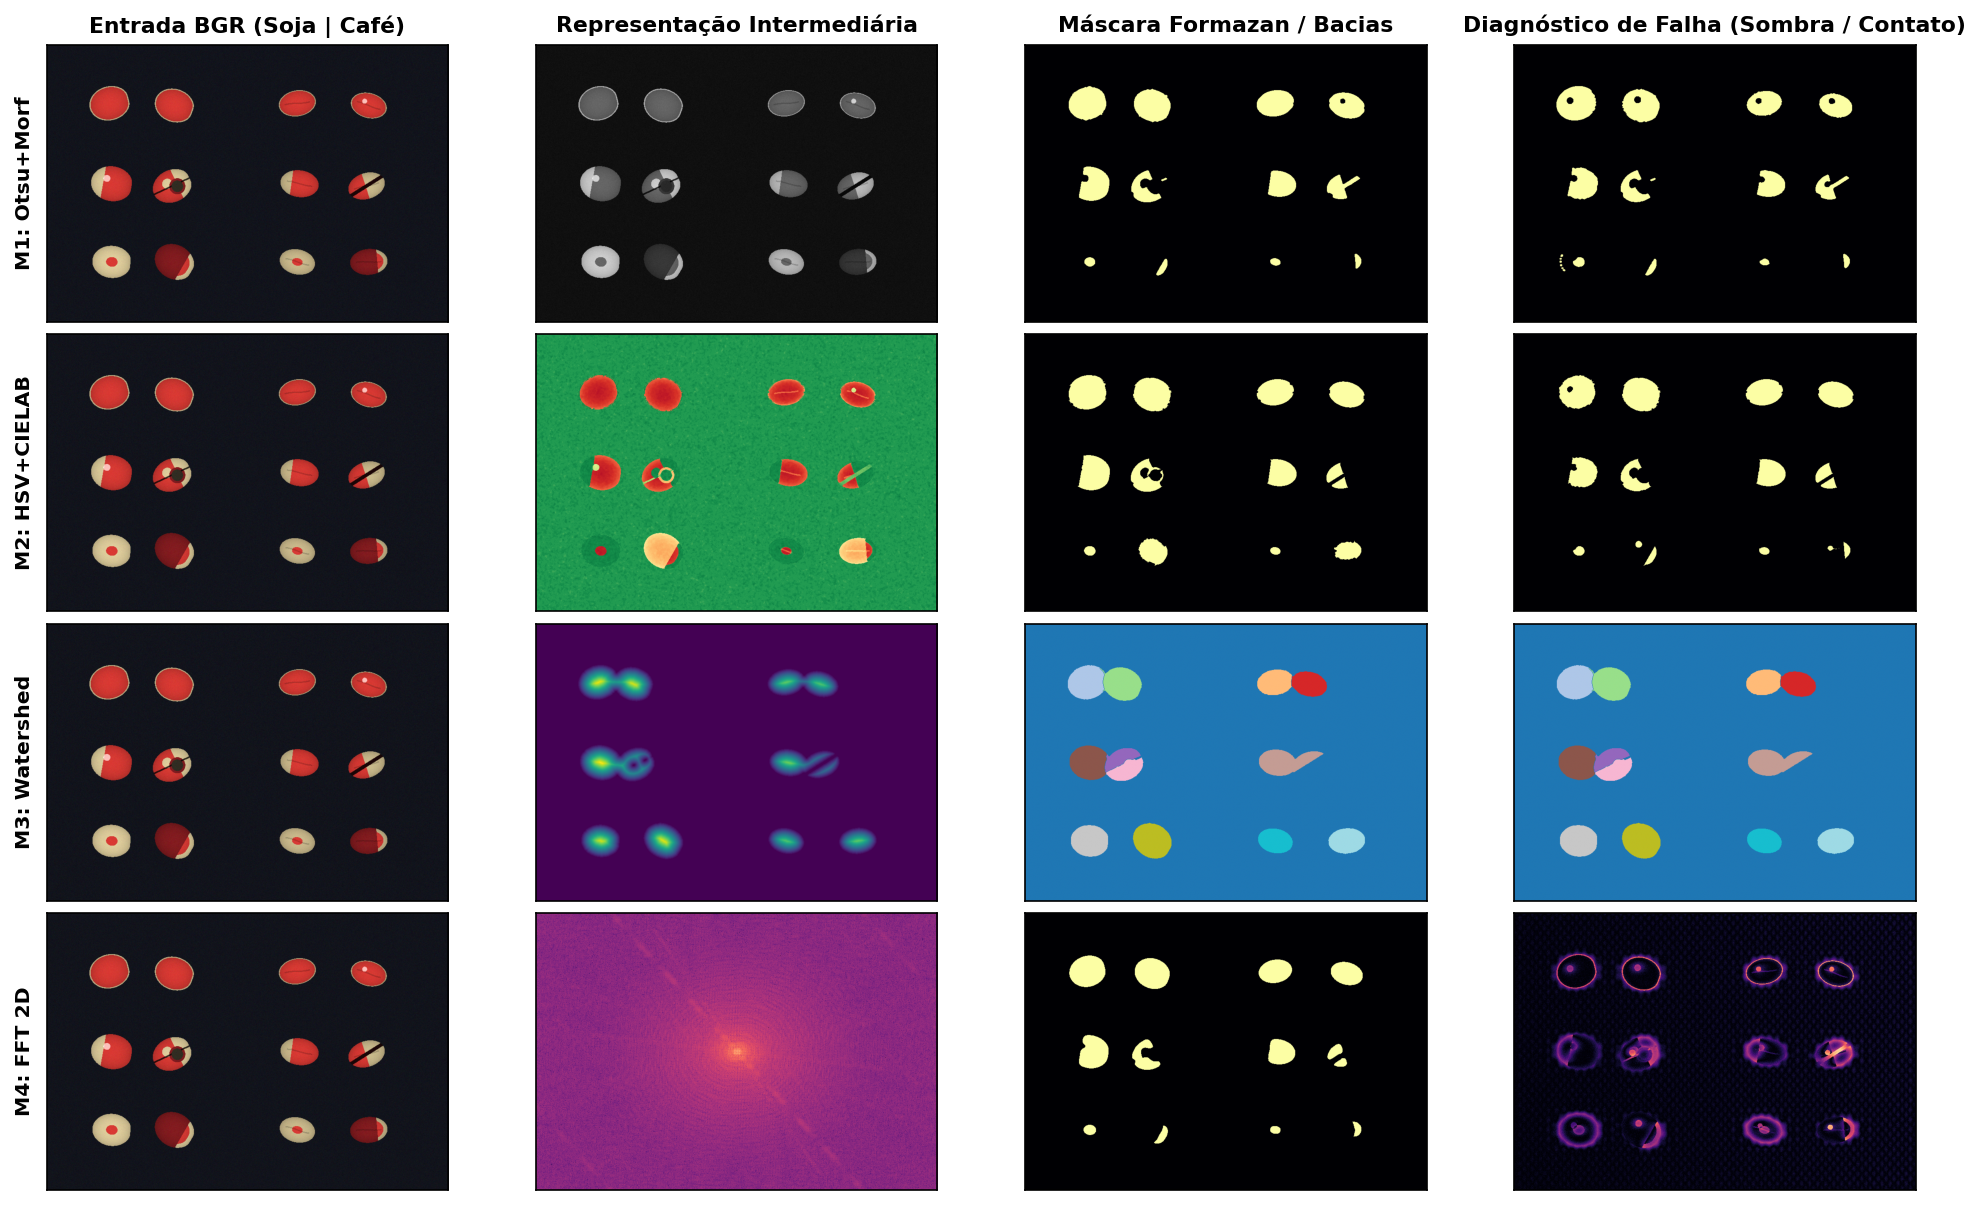

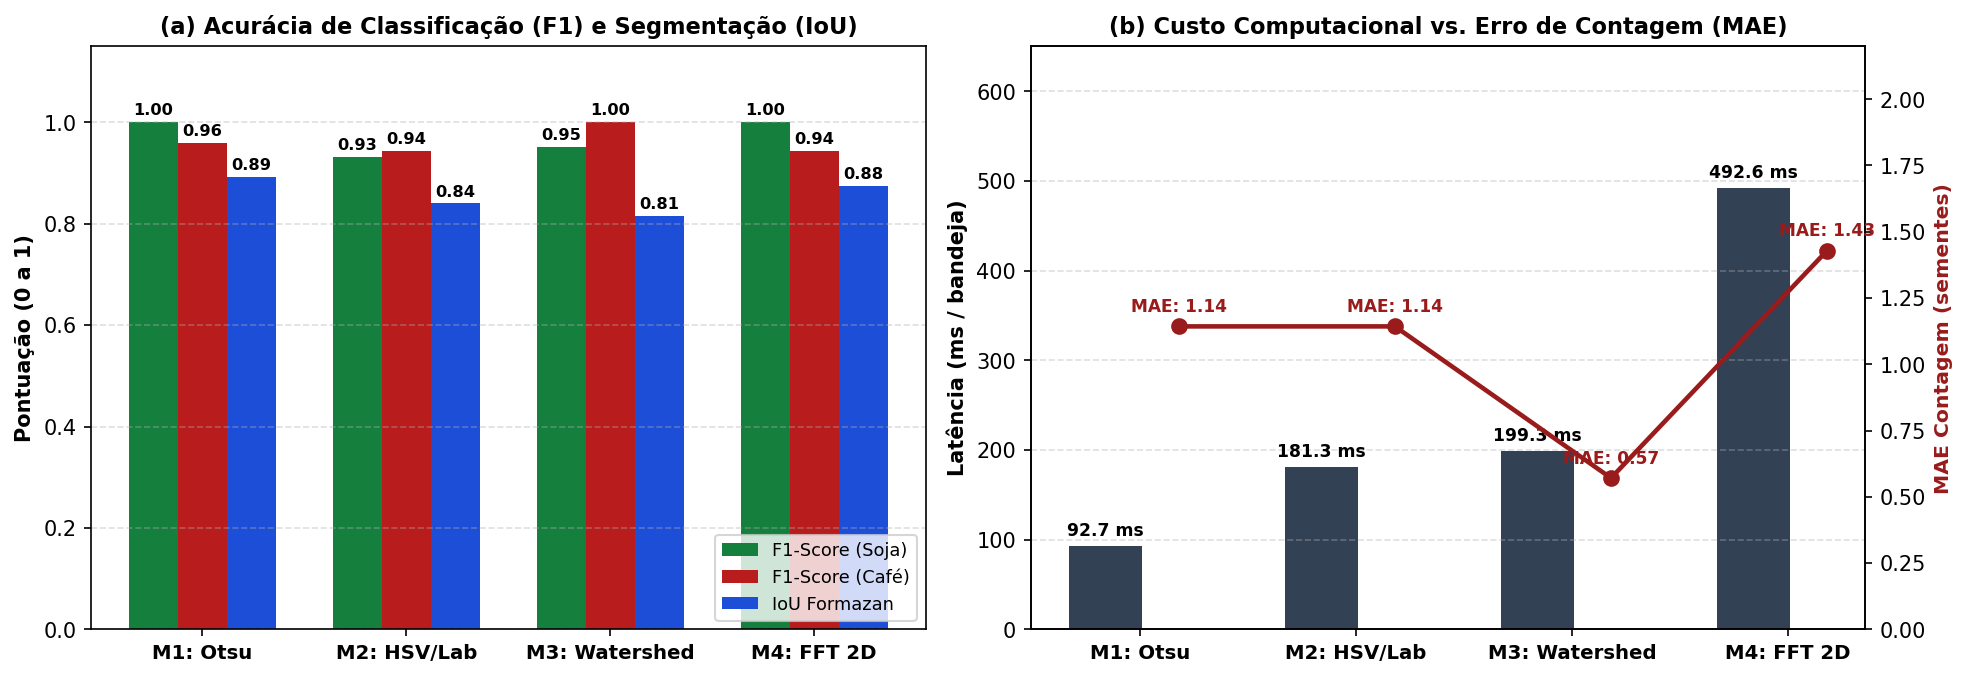

In [ ]:
def plotar_sintese_hibrida(resumo_medio: pd.DataFrame, resultados_por_cenario: Dict) -> None:
    b_padrao = resultados_por_cenario["padrao_0"]["bandeja"]
    m_padrao = resultados_por_cenario["padrao_0"]["metodos"]
    m_encost = resultados_por_cenario["encostadas_2"]["metodos"]
    m_sombra = resultados_por_cenario["iluminacao_sombra_4"]["metodos"]

    # Figura 1: Fluxo comparativo 4x4 dos pipelines
    fig, axes = plt.subplots(4, 4, figsize=(13.5, 8.0), dpi=150)
    fig.patch.set_facecolor("white")
    img_rgb = cv2.cvtColor(b_padrao["img_bgr"], cv2.COLOR_BGR2RGB)

    for col_i, tit in enumerate([
        "Entrada BGR (Soja | Café)",
        "Representação Intermediária",
        "Máscara Formazan / Bacias",
        "Diagnóstico de Falha (Sombra / Contato)",
    ]):
        axes[0, col_i].set_title(tit, fontsize=10.5, fontweight="bold", pad=6)

    linhas_cfg = [
        ("M1: Otsu+Morf", m_padrao[0]["intermediarias"]["Escala de Cinza"], "gray",
         m_padrao[0]["mascara_corada"], "inferno", m_sombra[0]["mascara_corada"], "inferno"),
        ("M2: HSV+CIELAB", m_padrao[1]["intermediarias"]["Canal a* (CIELAB)"], "RdYlGn_r",
         m_padrao[1]["mascara_corada"], "inferno", m_sombra[1]["mascara_corada"], "inferno"),
        ("M3: Watershed", m_encost[2]["intermediarias"]["Transf. Distância (EDT)"], "viridis",
         m_encost[2]["rotulos"], "tab20", m_encost[2]["rotulos"], "tab20"),
        ("M4: FFT 2D", m_padrao[3]["intermediarias"]["Espectro log|F(u,v)|"], "magma",
         m_padrao[3]["mascara_corada"], "inferno", m_sombra[3]["intermediarias"]["Realce Passa-Alta (Bordas)"], "magma"),
    ]

    for row_i, (lbl, im1, cm1, im2, cm2, im3, cm3) in enumerate(linhas_cfg):
        axes[row_i, 0].imshow(img_rgb)
        axes[row_i, 0].set_ylabel(lbl, fontsize=9.8, fontweight="bold", labelpad=6)
        axes[row_i, 1].imshow(im1, cmap=cm1)
        axes[row_i, 2].imshow(im2, cmap=cm2)
        axes[row_i, 3].imshow(im3, cmap=cm3)
        for col_i in range(4):
            axes[row_i, col_i].set_xticks([])
            axes[row_i, col_i].set_yticks([])

    plt.tight_layout(pad=0.6)
    fig.savefig(FIGURAS_DIR / "figura1_pipelines_hibridos.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)

    # Figura 2: Desempenho comparativo (F1, IoU, Tempo e MAE)
    fig2, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 4.6), dpi=150)
    fig2.patch.set_facecolor("white")
    nomes_curtos = ["M1: Otsu", "M2: HSV/Lab", "M3: Watershed", "M4: FFT 2D"]
    x = np.arange(len(nomes_curtos))
    w = 0.24

    b1 = ax1.bar(x - w, resumo_medio["F1 Soja"], width=w, color="#15803D", label="F1-Score (Soja)")
    b2 = ax1.bar(x, resumo_medio["F1 Café"], width=w, color="#B91C1C", label="F1-Score (Café)")
    b3 = ax1.bar(x + w, resumo_medio["IoU Corada (TZ)"], width=w, color="#1D4ED8", label="IoU Formazan")
    for grupo in (b1, b2, b3):
        for r in grupo:
            ax1.annotate(f"{r.get_height():.2f}", xy=(r.get_x() + r.get_width() / 2, r.get_height()),
                         xytext=(0, 2), textcoords="offset points", ha="center", va="bottom", fontsize=7.8, fontweight="bold")
    ax1.set_xticks(x)
    ax1.set_xticklabels(nomes_curtos, fontsize=9.5, fontweight="bold")
    ax1.set_ylim(0, 1.15)
    ax1.set_ylabel("Pontuação (0 a 1)", fontsize=10, fontweight="bold")
    ax1.set_title("(a) Acurácia de Classificação (F1) e Segmentação (IoU)", fontsize=10.8, fontweight="bold")
    ax1.legend(loc="lower right", fontsize=8.5)
    ax1.grid(axis="y", linestyle="--", alpha=0.4)

    tempos = resumo_medio["Tempo (ms)"].values
    maes = resumo_medio["MAE Contagem"].values
    barras_t = ax2.bar(x - 0.16, tempos, width=0.34, color="#334155", label="Tempo (ms)")
    for r in barras_t:
        ax2.annotate(f"{r.get_height():.1f} ms", xy=(r.get_x() + r.get_width() / 2, r.get_height()),
                     xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontsize=8.3, fontweight="bold")
    ax2.set_xticks(x)
    ax2.set_xticklabels(nomes_curtos, fontsize=9.5, fontweight="bold")
    ax2.set_ylim(0, max(tempos) * 1.32)
    ax2.set_ylabel("Latência (ms / bandeja)", fontsize=10, fontweight="bold")
    ax2.set_title("(b) Custo Computacional vs. Erro de Contagem (MAE)", fontsize=10.8, fontweight="bold")
    ax2.grid(axis="y", linestyle="--", alpha=0.4)

    ax2_t = ax2.twinx()
    ax2_t.plot(x + 0.18, maes, color="#991B1B", marker="o", linewidth=2.2, markersize=7)
    ax2_t.set_ylabel("MAE Contagem (sementes)", fontsize=9.8, fontweight="bold", color="#991B1B")
    ax2_t.set_ylim(0, max(2.2, max(maes) * 1.45))
    for xi, mv in zip(x + 0.18, maes):
        ax2_t.annotate(f"MAE: {mv:.2f}", xy=(xi, mv), xytext=(0, 7), textcoords="offset points",
                       ha="center", fontsize=8.2, fontweight="bold", color="#991B1B")

    plt.tight_layout(pad=1.0)
    fig2.savefig(FIGURAS_DIR / "grafico1_metricas_hibridas.png", dpi=200, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig2)


plotar_sintese_hibrida(resumo_hibrido, resultados_hibrido)


## 6. Validação de Generalização Multi-Espécie: *Phaseolus spp.* (Feijão Comum)

A extensão da arquitetura híbrida (Café e Soja) para sementes de feijão comum (*Phaseolus spp.*) sustenta-se em dois fundamentos convergentes:

1. **Homologia Botânica e Bioquímica:** Assim como a soja (*Glycine max*), o feijão (*Phaseolus vulgaris* L.) pertence à família *Fabaceae*, apresentando cotilédones volumosos nos quais a atividade das desidrogenases converte o sal de tetrazólio em formazan róseo-carmim segundo a mesma cinética de oxirredução.
2. **Alinhamento Normativo (RAS — BRASIL, 2009, p. 232 e 275; BHERING et al., 1999):** O protocolo laboratorial prescreve pré-umedecimento entre papel (18–24 h a 25 °C) ou pré-condicionamento em caixa *gerbox* com tela modificada sobre lâmina d'água (16–24 h a 20–25 °C, prevenindo danos por embebição em lotes de baixa umidade), seguido de imersão da semente intacta em solução de TTC a 0,075%–0,1% por 2–4 h a 40 °C no escuro. Na etapa de avaliação, efetua-se o corte longitudinal através do eixo embrionário e a remoção completa do tegumento pigmentado, classificando-se como viáveis os exemplares cuja área não colorida ou necrosada não excede metade dos cotilédones (`limiar_viavel = 0,50`), um terço da ponta da radícula ou um quarto da plúmula.

A bateria experimental a seguir comprova a capacidade de generalização dos quatro pipelines calibrados sobre 36 cotilédones bipartidos de *Phaseolus spp.* distribuídos em três condições ópticas (padrão, contato físico e gradiente de iluminação).


=== VALIDAÇÃO DE GENERALIZAÇÃO — PHASEOLUS SPP. (36 COTILÉDONES EM 3 REGIMES ÓPTICOS) ===
                                       Método  Precisão  Revocação  F1 Feijão  IoU Sementes  IoU Corada (TZ)  MAE Contagem  Tempo (ms)
           M1: Histograma (Otsu) + Morfologia     0.952        1.0      0.974         0.893            0.884         0.667      57.433
            M2: Espaços de Cor (HSV + CIELAB)     1.000        1.0      1.000         0.996            0.914         0.667      78.997
            M3: Watershed + Transf. Distância     1.000        1.0      1.000         0.960            0.913         1.000     115.107
M4: Domínio da Frequência (FFT - Butterworth)     1.000        1.0      1.000         0.878            0.878         0.667     242.847


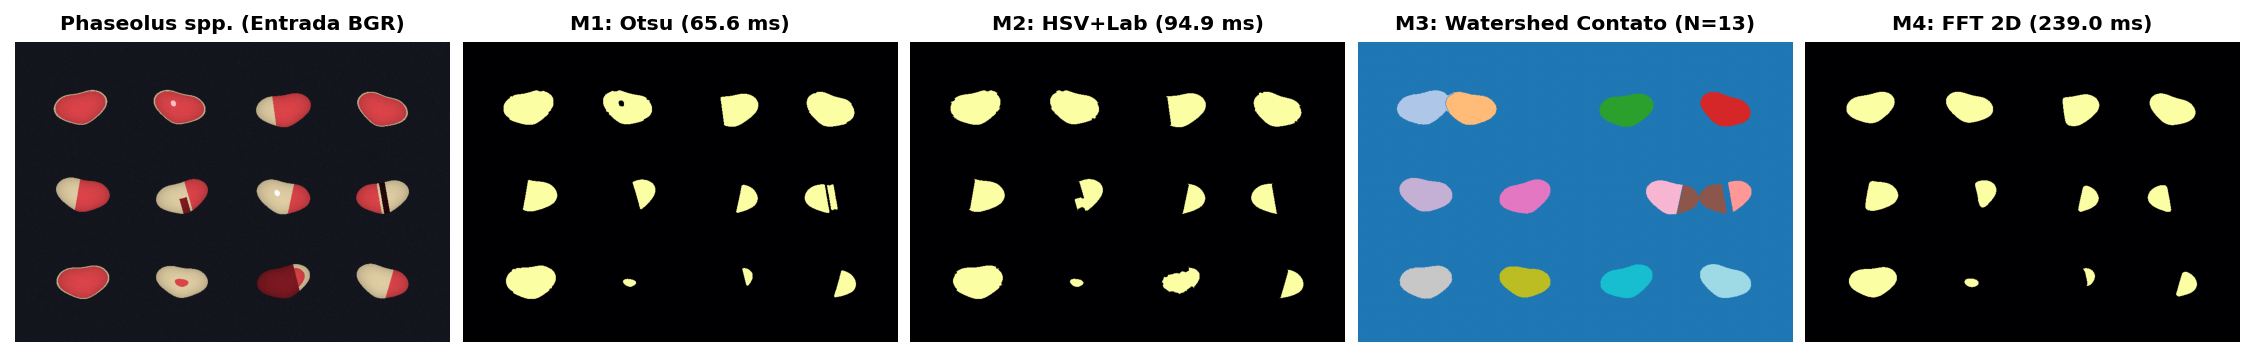

In [ ]:
def executar_validacao_feijao() -> Tuple[pd.DataFrame, Dict]:
    cenarios_f = [("padrao", 50), ("encostadas", 51), ("iluminacao_sombra", 52)]
    registros_f = []
    res_feijao = {}

    for nome_c, off in cenarios_f:
        bandeja_f = gerar_bandeja_feijao_tz(nome_c, seed_offset=off)
        img_f = bandeja_f["img_bgr"]
        saidas_f = [
            pipeline_1_histograma_morfologia(img_f, "feijao"),
            pipeline_2_espacos_cor_hsv_cielab(img_f, "feijao"),
            pipeline_3_watershed_distancia(img_f, "feijao"),
            pipeline_4_dominio_frequencia_fft(img_f, "feijao", "butterworth"),
        ]
        res_feijao[nome_c] = {"bandeja": bandeja_f, "metodos": saidas_f}
        for r in saidas_f:
            registros_f.append(avaliar_metodo_em_bandeja(r, bandeja_f))

    df_f = pd.DataFrame(registros_f)
    cols = ["Precisão", "Revocação", "F1 Feijão", "IoU Sementes", "IoU Corada (TZ)", "MAE Contagem", "Tempo (ms)"]
    resumo_f = df_f.groupby("Método", sort=False)[cols].mean().round(3).reset_index()
    return resumo_f, res_feijao


resumo_feijao, resultados_feijao = executar_validacao_feijao()
resumo_feijao.to_csv(RESULTADOS_DIR / "tabela_generalizacao_feijao.csv", index=False)

print("=== VALIDAÇÃO DE GENERALIZAÇÃO — PHASEOLUS SPP. (36 COTILÉDONES EM 3 REGIMES ÓPTICOS) ===")
print(resumo_feijao.to_string(index=False))

# Prancha visual comparativa para Phaseolus spp.
bf_pad = resultados_feijao["padrao"]["bandeja"]
mf_pad = resultados_feijao["padrao"]["metodos"]
mf_enc = resultados_feijao["encostadas"]["metodos"]

fig_f, axes_f = plt.subplots(1, 5, figsize=(15.0, 3.4), dpi=150)
fig_f.patch.set_facecolor("white")
axes_f[0].imshow(cv2.cvtColor(bf_pad["img_bgr"], cv2.COLOR_BGR2RGB))
axes_f[0].set_title("Phaseolus spp. (Entrada BGR)", fontsize=9.8, fontweight="bold")
axes_f[1].imshow(mf_pad[0]["mascara_corada"], cmap="inferno")
axes_f[1].set_title(f"M1: Otsu ({mf_pad[0]['tempo_ms']:.1f} ms)", fontsize=9.8, fontweight="bold")
axes_f[2].imshow(mf_pad[1]["mascara_corada"], cmap="inferno")
axes_f[2].set_title(f"M2: HSV+Lab ({mf_pad[1]['tempo_ms']:.1f} ms)", fontsize=9.8, fontweight="bold")
axes_f[3].imshow(mf_enc[2]["rotulos"], cmap="tab20")
axes_f[3].set_title(f"M3: Watershed Contato (N={len(mf_enc[2]['df_sementes'])})", fontsize=9.8, fontweight="bold")
axes_f[4].imshow(mf_pad[3]["mascara_corada"], cmap="inferno")
axes_f[4].set_title(f"M4: FFT 2D ({mf_pad[3]['tempo_ms']:.1f} ms)", fontsize=9.8, fontweight="bold")
for ax in axes_f:
    ax.axis("off")
plt.tight_layout(pad=0.6)
fig_f.savefig(FIGURAS_DIR / "figura_generalizacao_feijao.png", dpi=200, bbox_inches="tight", facecolor="white")
plt.show()
plt.close(fig_f)


## 7. Módulo de Demonstração ao Vivo e Validação em Bancada Laboratorial

Esta seção integra o motor de aquisição óptica em tempo real aos quatro pipelines calibrados, constituindo o ambiente de demonstração ao vivo para inspeção de amostras reais de laboratório (*Phaseolus spp.*, *Glycine max* ou *Coffea arabica*). O módulo opera em três estágios encadeados:

1. **Aquisição e Normalização Espacial (`adquirir_imagem_laboratorio`):** realiza a captura direta via câmera/webcam pelo protocolo WebRTC no navegador do ambiente Colab, o carregamento de imagem local ou a seleção de bandeja de referência, aplicando redimensionamento proporcional automático (teto de 1200 px no maior eixo) para preservar baixa latência em câmeras de alta resolução.
2. **Inferência Simultânea em Tempo Real (`executar_demonstracao_ao_vivo`):** executa paralelamente os quatro paradigmas sobre a amostra adquirida, sobrepõe à imagem original os identificadores sequenciais (`S01`, `S02`, ...), a fração de tecido ativo (%) e a classe predita, e apresenta a tabela diagnóstica de viabilidade do lote.
3. **Confronto de Concordância com Laudo Especialista (`avaliar_concordancia_laudo`):** calcula as métricas de concordância (Acurácia, Precisão, Revocação e F1-Score) entre a classificação computacional e o gabarito técnico emitido pelo laboratório.


In [ ]:
def normalizar_resolucao(img_bgr: np.ndarray, max_lado: int = 1200) -> np.ndarray:
    """Redimensiona imagens de alta resolução preservando a razão de aspecto para inferência em tempo real."""
    h, w = img_bgr.shape[:2]
    maior = max(h, w)
    if maior <= max_lado:
        return img_bgr
    fator = max_lado / float(maior)
    return cv2.resize(img_bgr, (int(w * fator), int(h * fator)), interpolation=cv2.INTER_AREA)


def capturar_camera_colab(usar_camera_traseira: bool = True, qualidade_jpeg: float = 0.94) -> np.ndarray:
    """Aciona o fluxo de vídeo WebRTC diretamente no navegador do Google Colab e retorna matriz BGR."""
    from IPython.display import Javascript, display
    from google.colab.output import eval_js

    facing = "environment" if usar_camera_traseira else "user"
    js = Javascript(f'''
    async function captureTray(quality) {{
      const box = document.createElement('div');
      box.style.marginBottom = '10px';
      const btn = document.createElement('button');
      btn.textContent = 'Capturar Amostra';
      btn.style.cssText = 'padding:10px 20px;font-size:14px;font-weight:bold;background:#14532d;color:white;border:none;border-radius:6px;cursor:pointer;margin-bottom:8px;';
      box.appendChild(btn);

      const video = document.createElement('video');
      video.style.cssText = 'display:block;max-width:100%;border:2px solid #14532d;border-radius:6px;';
      const stream = await navigator.mediaDevices.getUserMedia({{
        video: {{ facingMode: "{facing}", width: {{ ideal: 1920 }}, height: {{ ideal: 1080 }} }}
      }});
      document.body.appendChild(box);
      box.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => btn.onclick = resolve);

      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getTracks().forEach(t => t.stop());
      box.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }}
    ''')
    display(js)
    data_url = eval_js(f"captureTray({qualidade_jpeg})")
    raw = base64.b64decode(data_url.split(",")[1])
    img_bgr = cv2.imdecode(np.frombuffer(raw, dtype=np.uint8), cv2.IMREAD_COLOR)
    ts = datetime.now().strftime("%Y%m%d_%H%M%S")
    cv2.imwrite(str(DATA_DIR_LAB / f"captura_{ts}.png"), img_bgr)
    return normalizar_resolucao(img_bgr)


def adquirir_imagem_laboratorio(
    modo: str = "demo_feijao",
    caminho_arquivo: Optional[str] = None,
) -> np.ndarray:
    """
    Interface unificada de entrada óptica:
      - 'camera'      : captura direta via webcam/câmera no Google Colab (WebRTC);
      - 'upload'      : importação direta de imagem a partir do dispositivo local;
      - 'arquivo'     : leitura de arquivo existente em disco (`caminho_arquivo`);
      - 'demo_feijao' : amostra calibrada de Phaseolus spp. para verificação imediata;
      - 'demo_hibrido': amostra calibrada híbrida (Glycine max + Coffea arabica).
    """
    if modo == "camera":
        return capturar_camera_colab(usar_camera_traseira=True)
    if modo == "upload":
        from google.colab import files
        enviados = files.upload()
        nome_arq = next(iter(enviados.keys()))
        img = cv2.imdecode(np.frombuffer(enviados[nome_arq], dtype=np.uint8), cv2.IMREAD_COLOR)
        return normalizar_resolucao(img)
    if modo == "arquivo" and caminho_arquivo:
        img = cv2.imread(str(caminho_arquivo), cv2.IMREAD_COLOR)
        if img is None:
            raise FileNotFoundError(f"Imagem não localizada em: {caminho_arquivo}")
        return normalizar_resolucao(img)
    if modo == "demo_hibrido":
        return gerar_bandeja_hibrida_tz("padrao", seed_offset=10)["img_bgr"]
    return gerar_bandeja_feijao_tz("padrao", seed_offset=77)["img_bgr"]


def executar_demonstracao_ao_vivo(
    img_bgr: np.ndarray,
    cultura_alvo: str = "feijao",
    metodo_referencia_idx: int = 2,
) -> Tuple[List[Dict], pd.DataFrame]:
    """Executa os quatro paradigmas sobre a amostra adquirida e renderiza o painel de inspeção ao vivo."""
    saidas = [
        pipeline_1_histograma_morfologia(img_bgr, cultura_alvo),
        pipeline_2_espacos_cor_hsv_cielab(img_bgr, cultura_alvo),
        pipeline_3_watershed_distancia(img_bgr, cultura_alvo),
        pipeline_4_dominio_frequencia_fft(img_bgr, cultura_alvo, "butterworth"),
    ]

    fig, axes = plt.subplots(2, 3, figsize=(13.8, 7.0), dpi=150)
    fig.patch.set_facecolor("white")

    vis_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    df_ref = saidas[metodo_referencia_idx]["df_sementes"]
    raio_vis = max(24, int(min(img_bgr.shape[:2]) * 0.055))
    for _, row in df_ref.iterrows():
        sid = int(row["id_semente"])
        cx, cy = int(row["cx"]), int(row["cy"])
        cor = (34, 197, 94) if row["classe"] == "Viável" else (239, 68, 68)
        cv2.circle(vis_rgb, (cx, cy), raio_vis, cor, 3)
        cv2.putText(vis_rgb, f"S{sid:02d}", (cx - 22, cy - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.58, (255, 255, 0), 2, cv2.LINE_AA)
        cv2.putText(vis_rgb, f"{int(row['fracao_corada'] * 100)}%", (cx - 22, cy + 16), cv2.FONT_HERSHEY_SIMPLEX, 0.50, (255, 255, 255), 2, cv2.LINE_AA)

    axes[0, 0].imshow(vis_rgb)
    axes[0, 0].set_title(f"(a) Inspeção Ao Vivo — {cultura_alvo.capitalize()} (N={len(df_ref)})", fontsize=10.2, fontweight="bold")
    axes[0, 0].axis("off")

    axes[0, 1].imshow(saidas[0]["mascara_corada"], cmap="inferno")
    axes[0, 1].set_title(f"(b) M1: Otsu+Morf ({saidas[0]['tempo_ms']:.1f} ms)", fontsize=10.2, fontweight="bold")
    axes[0, 1].axis("off")

    axes[0, 2].imshow(saidas[1]["mascara_corada"], cmap="inferno")
    axes[0, 2].set_title(f"(c) M2: HSV+CIELAB ({saidas[1]['tempo_ms']:.1f} ms)", fontsize=10.2, fontweight="bold")
    axes[0, 2].axis("off")

    axes[1, 0].imshow(saidas[2]["rotulos"], cmap="tab20")
    axes[1, 0].set_title(f"(d) M3: Watershed EDT ({saidas[2]['tempo_ms']:.1f} ms)", fontsize=10.2, fontweight="bold")
    axes[1, 0].axis("off")

    axes[1, 1].imshow(saidas[3]["mascara_corada"], cmap="inferno")
    axes[1, 1].set_title(f"(e) M4: FFT Butterworth ({saidas[3]['tempo_ms']:.1f} ms)", fontsize=10.2, fontweight="bold")
    axes[1, 1].axis("off")

    nomes = ["M1: Otsu", "M2: HSV/Lab", "M3: Watershed", "M4: FFT 2D"]
    viav = [int((r["df_sementes"]["classe"] == "Viável").sum()) for r in saidas]
    inviav = [int((r["df_sementes"]["classe"] == "Inviável").sum()) for r in saidas]
    xp = np.arange(len(nomes))
    axes[1, 2].bar(xp - 0.16, viav, width=0.32, color="#16A34A", label="Viáveis")
    axes[1, 2].bar(xp + 0.16, inviav, width=0.32, color="#DC2626", label="Inviáveis")
    axes[1, 2].set_xticks(xp)
    axes[1, 2].set_xticklabels(nomes, fontsize=8.8, fontweight="bold")
    axes[1, 2].set_ylabel("Nº de Exemplares", fontsize=9.2, fontweight="bold")
    axes[1, 2].set_ylim(0, max(8, max(viav + inviav) + 3))
    axes[1, 2].set_title("(f) Síntese de Viabilidade do Lote", fontsize=10.2, fontweight="bold")
    axes[1, 2].legend(fontsize=8.4)
    axes[1, 2].grid(axis="y", linestyle="--", alpha=0.4)

    plt.tight_layout(pad=0.8)
    plt.show()
    plt.close(fig)

    resumo_lote = pd.DataFrame([
        {
            "Método": r["metodo"],
            "Detectadas": len(r["df_sementes"]),
            "Viáveis": int((r["df_sementes"]["classe"] == "Viável").sum()),
            "Inviáveis": int((r["df_sementes"]["classe"] == "Inviável").sum()),
            "Viabilidade (%)": round(
                (int((r["df_sementes"]["classe"] == "Viável").sum()) / max(1, len(r["df_sementes"]))) * 100.0, 1
            ),
            "Tempo (ms)": round(r["tempo_ms"], 2),
        }
        for r in saidas
    ])
    return saidas, resumo_lote


def avaliar_concordancia_laudo(saidas: List[Dict], laudo_especialista: Dict[int, str]) -> pd.DataFrame:
    """Confronta as predições de cada paradigma com o laudo oficial emitido em bancada."""
    linhas = []
    for r in saidas:
        df_s = r["df_sementes"]
        mapa_pred = {int(row["id_semente"]): row["classe"] for _, row in df_s.iterrows()}
        y_t, y_p, divergencias = [], [], []
        for sid, cls_real in sorted(laudo_especialista.items()):
            yt_i = 1 if cls_real == "Viável" else 0
            yp_i = 1 if mapa_pred.get(sid, "Inviável") == "Viável" else 0
            y_t.append(yt_i)
            y_p.append(yp_i)
            if yt_i != yp_i:
                divergencias.append(f"S{sid:02d}")
        prec, rec, f1 = calc_prf1(y_t, y_p)
        acur = sum(1 for a, b in zip(y_t, y_p) if a == b) / max(1, len(y_t))
        linhas.append({
            "Método": r["metodo"],
            "Acurácia": round(acur, 3),
            "Precisão": round(prec, 3),
            "Revocação": round(rec, 3),
            "F1-Score": round(f1, 3),
            "Divergências": ", ".join(divergencias) if divergencias else "Nenhuma",
        })
    return pd.DataFrame(linhas)


print("Módulo de demonstração ao vivo e validação de concordância carregado.")


Módulo de demonstração ao vivo e validação de concordância carregado.


### 7.1 Interface Interativa de Aquisição, Processamento e Avaliação em Tempo Real

A célula seguinte instancia uma interface gráfica interativa integrada ao ambiente de execução, permitindo selecionar a espécie agrícola, ajustar o limiar bioquímico de viabilidade, adquirir imagens por câmera WebRTC, carregamento de arquivo local ou conjuntos de referência, e confrontar imediatamente as predições dos quatro paradigmas com o laudo de bancada sem necessidade de edição manual de código.


In [ ]:
# Interface interativa de bancada e demonstração ao vivo (compatível com ipywidgets v7/v8 no Google Colab)
_ESTADO_SESSAO = {
    "img_bgr": None,
    "saidas": None,
    "cultura": "feijao",
}


def _interpretar_laudo_texto(texto: str) -> Dict[int, str]:
    """Converte sequência abreviada ('V, V, I, ...' ou 'Viável, Inviável, ...') em dicionário {id: classe}."""
    tokens = [t.strip().upper() for t in texto.replace(";", ",").replace("\n", ",").split(",") if t.strip()]
    mapa: Dict[int, str] = {}
    for idx_t, tok in enumerate(tokens, start=1):
        if tok.startswith("V") or tok == "1":
            mapa[idx_t] = "Viável"
        elif tok.startswith("I") or tok == "0":
            mapa[idx_t] = "Inviável"
    return mapa


def _extrair_bytes_upload(valor_upload) -> Optional[bytes]:
    """Extrai os bytes do arquivo carregado de forma compatível com ipywidgets v7 (dict) e v8 (tuple)."""
    if not valor_upload:
        return None
    if isinstance(valor_upload, dict):
        primeiro = next(iter(valor_upload.values()))
        return bytes(primeiro["content"])
    if isinstance(valor_upload, (tuple, list)) and len(valor_upload) > 0:
        primeiro = valor_upload[0]
        return bytes(primeiro["content"])
    return None


def iniciar_interface_bancada() -> None:
    try:
        import ipywidgets as widgets
        from IPython.display import clear_output, display
    except ImportError:
        img_demo = adquirir_imagem_laboratorio(modo="demo_feijao")
        saidas_demo, tabela_demo = executar_demonstracao_ao_vivo(img_demo, cultura_alvo="feijao", metodo_referencia_idx=1)
        print("=== DIAGNÓSTICO EM TEMPO REAL — ESPÉCIE: FEIJAO (PHASEOLUS SPP.) ===")
        print(tabela_demo.to_string(index=False))
        laudo_padrao = _interpretar_laudo_texto("V, V, V, V, V, I, I, I, V, I, I, I")
        df_conc = avaliar_concordancia_laudo(saidas_demo, laudo_padrao)
        print("\n=== MATRIZ DE CONCORDÂNCIA COM O LAUDO DE BANCADA (PHASEOLUS SPP.) ===")
        print(df_conc.to_string(index=False))
        return

    titulo_html = widgets.HTML(
        value=(
            "<div style='background:#14532d;color:#ffffff;padding:10px 14px;border-radius:6px;"
            "font-family:sans-serif;margin-bottom:8px;'>"
            "<div style='font-size:15px;font-weight:700;'>Estação Interativa de Análise de Sementes — Teste de Tetrazólio (PDI)</div>"
            "<div style='font-size:12px;color:#dcfce7;'>Seleção de perfil multi-espécie, aquisição óptica (Câmera / Upload / Referência) e validação de concordância em tempo real</div>"
            "</div>"
        )
    )

    dd_cultura = widgets.Dropdown(
        options=[
            ("Feijão Comum — Phaseolus spp. (RAS 50%)", "feijao"),
            ("Soja — Glycine max (62%)", "soja"),
            ("Café — Coffea arabica (58%)", "cafe"),
            ("Matriz Híbrida — Soja & Café", "hibrido"),
        ],
        value="feijao",
        description="Espécie:",
        style={"description_width": "85px"},
        layout=widgets.Layout(width="340px"),
    )

    dd_ref = widgets.Dropdown(
        options=[
            ("M2: HSV + CIELAB (Cromático)", 1),
            ("M3: Watershed + EDT (Separação)", 2),
            ("M1: Otsu + Morfologia", 0),
            ("M4: FFT 2D Butterworth", 3),
        ],
        value=1,
        description="Referência:",
        style={"description_width": "85px"},
        layout=widgets.Layout(width="310px"),
    )

    sl_limiar = widgets.IntSlider(
        value=50,
        min=30,
        max=85,
        step=1,
        description="Limiar (%):",
        style={"description_width": "85px"},
        layout=widgets.Layout(width="340px"),
    )

    btn_camera = widgets.Button(
        description="Capturar via Câmera",
        button_style="success",
        icon="camera",
        layout=widgets.Layout(width="185px", height="36px"),
    )
    uploader = widgets.FileUpload(
        accept=".png,.jpg,.jpeg,.bmp,.tif,.tiff",
        multiple=False,
        description="Carregar Imagem",
        layout=widgets.Layout(width="195px", height="36px"),
    )
    btn_demo_feijao = widgets.Button(
        description="Referência: Feijão",
        button_style="info",
        icon="leaf",
        layout=widgets.Layout(width="175px", height="36px"),
    )
    btn_demo_hibrido = widgets.Button(
        description="Referência: Café & Soja",
        button_style="primary",
        icon="th",
        layout=widgets.Layout(width="195px", height="36px"),
    )
    btn_reprocessar = widgets.Button(
        description="Reavaliar Amostra Atual",
        button_style="warning",
        icon="refresh",
        layout=widgets.Layout(width="195px", height="36px"),
    )

    txt_laudo = widgets.Text(
        value="V, V, V, V, V, I, I, I, V, I, I, I",
        description="Laudo (S01..SN):",
        placeholder="Sequência separada por vírgula: V (Viável) ou I (Inviável)",
        style={"description_width": "115px"},
        layout=widgets.Layout(width="520px"),
    )
    btn_concordancia = widgets.Button(
        description="Calcular Concordância",
        button_style="success",
        icon="check",
        layout=widgets.Layout(width="195px", height="32px"),
    )

    out_painel = widgets.Output()
    out_laudo = widgets.Output()

    def _ao_trocar_cultura(change):
        chave = change["new"]
        if chave in PERFIS_ESPECIE:
            sl_limiar.value = round(PERFIS_ESPECIE[chave]["limiar_viavel"] * 100)

    dd_cultura.observe(_ao_trocar_cultura, names="value")

    def _processar_e_exibir(img_bgr: np.ndarray, origem_label: str) -> None:
        cult = dd_cultura.value
        if cult in PERFIS_ESPECIE:
            PERFIS_ESPECIE[cult]["limiar_viavel"] = sl_limiar.value / 100.0
        _ESTADO_SESSAO["img_bgr"] = img_bgr
        _ESTADO_SESSAO["cultura"] = cult

        with out_painel:
            clear_output(wait=True)
            print(f"Origem: {origem_label} | Resolução normalizada: {img_bgr.shape[1]}x{img_bgr.shape[0]} px | Perfil ativo: {cult.upper()} (limiar {sl_limiar.value}%)")
            saidas, tab_lote = executar_demonstracao_ao_vivo(
                img_bgr, cultura_alvo=cult, metodo_referencia_idx=dd_ref.value
            )
            _ESTADO_SESSAO["saidas"] = saidas
            print(f"=== DIAGNÓSTICO EM TEMPO REAL — {cult.upper()} ===")
            print(tab_lote.to_string(index=False))

        with out_laudo:
            clear_output(wait=True)

    def _on_camera(_):
        with out_painel:
            clear_output(wait=True)
            print("Aguardando captura óptica via câmera WebRTC...")
        img = adquirir_imagem_laboratorio(modo="camera")
        _processar_e_exibir(img, "Câmera WebRTC (Tempo Real)")

    def _on_upload(change):
        conteudo = _extrair_bytes_upload(change["new"])
        if conteudo is None:
            return
        img = cv2.imdecode(np.frombuffer(conteudo, dtype=np.uint8), cv2.IMREAD_COLOR)
        if img is not None:
            _processar_e_exibir(normalizar_resolucao(img), "Upload de Arquivo Local")

    def _on_demo_feijao(_):
        dd_cultura.value = "feijao"
        img = adquirir_imagem_laboratorio(modo="demo_feijao")
        _processar_e_exibir(img, "Amostra Calibrada — Phaseolus spp. (Feijão)")

    def _on_demo_hibrido(_):
        dd_cultura.value = "hibrido"
        img = adquirir_imagem_laboratorio(modo="demo_hibrido")
        _processar_e_exibir(img, "Amostra Calibrada — Matriz Híbrida (Café & Soja)")

    def _on_reprocessar(_):
        if _ESTADO_SESSAO["img_bgr"] is not None:
            _processar_e_exibir(_ESTADO_SESSAO["img_bgr"], "Reavaliação com Novos Parâmetros")

    def _on_concordancia(_):
        with out_laudo:
            clear_output(wait=True)
            if _ESTADO_SESSAO["saidas"] is None:
                print("Nenhuma amostra processada na sessão atual.")
                return
            laudo_dict = _interpretar_laudo_texto(txt_laudo.value)
            if not laudo_dict:
                print("Formato de laudo inválido. Utilize sequência separada por vírgulas (ex.: V, V, I, ...).")
                return
            df_c = avaliar_concordancia_laudo(_ESTADO_SESSAO["saidas"], laudo_dict)
            print(f"=== MATRIZ DE CONCORDÂNCIA COM O LAUDO DE BANCADA ({len(laudo_dict)} EXEMPLARES) ===")
            print(df_c.to_string(index=False))

    btn_camera.on_click(_on_camera)
    uploader.observe(_on_upload, names="value")
    btn_demo_feijao.on_click(_on_demo_feijao)
    btn_demo_hibrido.on_click(_on_demo_hibrido)
    btn_reprocessar.on_click(_on_reprocessar)
    btn_concordancia.on_click(_on_concordancia)

    painel_controles = widgets.VBox([
        titulo_html,
        widgets.HBox([dd_cultura, dd_ref, sl_limiar]),
        widgets.HBox([btn_camera, uploader, btn_demo_feijao, btn_demo_hibrido, btn_reprocessar]),
        widgets.HBox([txt_laudo, btn_concordancia]),
        out_painel,
        out_laudo,
    ])
    display(painel_controles)

    # Carga inicial automática da amostra demonstrativa de Phaseolus spp.
    _on_demo_feijao(None)


iniciar_interface_bancada()
